# How fast can a polymer melt flow through a circular die?

*Python for Engineers: Case Studies from Calculator to Simulation* · Notebook 22 · Yanwei Wang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/python-for-engineers-case-studies/blob/main/notebooks/22_Polymer_Melt_Pipe_Flow_Carreau_Yasuda.ipynb)

**Audience:** first-year engineering students. No polymer science, rheology, calculus, or fluid mechanics course is assumed.

A familiar plastic object may begin as polymer pellets. In a processing machine, the polymer is heated and pushed through a narrow opening called a **die** before it cools into a shape. If the die is a straight circular passage, an engineer wants to know: *How much material passes through it for a given pressure, and how would changing its radius affect production?* The material may be much harder to move gently than it is to move rapidly. We can use a short program to connect that behavior to the speed across a die and the amount delivered each second.

This case study is based on **Y. Wang, “Steady isothermal flow of a Carreau–Yasuda model fluid in a straight circular tube,” *Journal of Non-Newtonian Fluid Mechanics* 310 (2022), 104937**, [doi:10.1016/j.jnnfm.2022.104937](https://doi.org/10.1016/j.jnnfm.2022.104937). The accompanying [research code and calculator](https://github.com/ktwyw/carreau-yasuda-pipe-flow) implement the paper's analytical and numerical approaches. A later, **not peer-reviewed** [2026 preprint](https://doi.org/10.20944/preprints202608.2093.v1) establishes a general monotone mapping and relates tube flow to flow in a plane channel; its geometric idea appears in an optional section. The parameters used below are the *illustrative model fluid* of the 2022 paper, **not measured properties of a specific polymer melt**. All teaching figures and notebook code here are newly constructed.

**How to run:** read the explanation, predict a simple outcome, run the next code cell, then explain any disagreement. Run from the first cell in order. Python 3.10+ with NumPy, Matplotlib, and SciPy is required. Every executable line has an explanatory comment beside it. Figures appear in the executed notebook and are saved as SVG and 300 dpi PNG in `figures_polymer_melt/`. The main story is complete before the optional research extensions.

<!-- pfe-study-guide -->
## Study guide

| | |
|---|---|
| **Status** | Optional · Extensions |
| **Time** | about 55 min of reading |
| **Before this** | Notebook 21 is a useful warm-up. |
| **Essential** | Sections 1–7, 9 and 12. |
| **Optional on a first reading** | Sections 8, 10 and 11, and the animation in Section 5. |
| **Next** | Any other extension. |

**You have understood this notebook if you can, without looking back:**

1. Explain shear-thinning, and what the Carreau–Yasuda parameters control.
2. Describe the chain pressure → stress → shear rate → velocity → flow rate, and where a root-finding step is needed.
3. Check the code against the Newtonian limit.
4. Explain why doubling the pressure more than doubles the flow of a shear-thinning melt.
5. Work backward from a production target to the pressure required.

**Not expected of you:** The hypergeometric formula and the research connection in Section 11.

*The comment on every code line is a reading aid. In your own programs, comment the reasons and the non-obvious steps.*

## 1. A die, a speed, and an amount per second

Our **polymer melt** is a flowing, heated polymer; this notebook does not simulate its melting. **Rheology** asks how a material responds to being deformed. **Processing** uses that response to predict quantities such as throughput and pressure loss. Our model studies a long, straight, circular *die*: the melt flows along its length while its axial speed $u(r)$ depends on distance $r$ from the center.

| Quantity | Symbol | Meaning | SI unit |
| --- | --- | --- | --- |
| Inner radius | $R$ | Center to the die wall | m |
| Die length | $L$ | Distance along the die | m |
| Pressure difference | $\Delta p$ | Inlet pressure less outlet pressure, for a horizontal die | Pa |
| Pressure gradient | $G=\Delta p/L$ | Pressure loss for each metre | Pa/m |
| Local speed | $u(r)$ | Melt speed at radius $r$ | m/s |
| Average speed | $\bar u$ | Speed averaged over cross-sectional area | m/s |
| Volume flow rate | $Q$ | Volume passing a cross-section per second | m³/s |
| Shear stress | $\tau$ | Tangential force per area | Pa |
| Shear rate | $\dot\gamma$ | Rate at which neighboring speeds differ | 1/s |
| Viscosity | $\eta$ | Stress divided by shear rate | Pa·s |

One pascal is one newton per square metre. A circle's area is $A=\pi R^2$, and $Q=A\bar u$. **Predict by hand:** a 10 mm-radius passage with a *uniform* speed of $0.10$ m/s would carry how many litres each minute? Use $1\,\mathrm{m^3}=1000$ L and $1\,\mathrm{min}=60$ s. The uniform speed is only a warm-up: our later velocity profile is nonuniform.

In [1]:
# Import numerical arrays for the sampled radii, flow curves, and integration.
import numpy as np
# NumPy 2.0 renamed np.trapz to np.trapezoid; this keeps the notebook working on NumPy 1.x as well.
if not hasattr(np, 'trapezoid'):
    # Point the new name at the old function so later np.trapezoid calls work on any NumPy version.
    np.trapezoid = np.trapz
# Import the plotting library used to create every original figure.
import matplotlib.pyplot as plt
# Import basic shapes for a simple, non-photographic die schematic.
from matplotlib.patches import Rectangle, FancyArrowPatch
# Import filesystem paths for predictable vector and raster figure exports.
from pathlib import Path
# Use a coherent typographic hierarchy and retain editable text in SVG files.
plt.rcParams.update({"font.size": 10, "axes.labelsize": 10, "axes.titlesize": 12, "svg.fonttype": "none", "figure.dpi": 125})
# Place exported figures beside this notebook's working directory.
figure_dir = Path("figures_polymer_melt")
# Make the directory on the first run and accept its existence on later runs.
figure_dir.mkdir(parents=True, exist_ok=True)
# Keep accessible colors consistent across comparisons.
colors = {"ink": "#233746", "blue": "#2166AC", "teal": "#008A80", "orange": "#D57B19", "rose": "#B54C68", "grey": "#6C7782"}
# Define one figure-output step so every plot has the same export quality.
def finish_figure(fig, stem):
    '''Save SVG and high-resolution PNG versions, then show the figure.'''
    # Store a scalable plot for readers preparing teaching notes or reports.
    fig.savefig(figure_dir / f"{stem}.svg", bbox_inches="tight")
    # Provide a high-resolution fallback for software without good SVG support.
    fig.savefig(figure_dir / f"{stem}.png", dpi=300, bbox_inches="tight")
    # Display the result in this notebook instead of leaving a hidden file only.
    plt.show()

In [2]:
# Use the 10 mm radius of the paper's illustrative tube in SI metres.
radius_m = 0.010
# Choose a simple uniform speed for a hand calculation, in metres per second.
warmup_speed_m_s = 0.10
# Compute the cross-sectional area in square metres.
area_m2 = np.pi * radius_m**2
# Multiply area by speed to obtain a volume rate in cubic metres per second.
warmup_q_m3_s = area_m2 * warmup_speed_m_s
# Convert seconds to minutes and cubic metres to litres.
warmup_q_l_min = warmup_q_m3_s * 60.0 * 1000.0
# Print a dimensional answer to compare with the hand prediction.
print(f"A = {area_m2:.7f} m²; uniform-flow Q = {warmup_q_l_min:.2f} L/min")
# Check that converting L/min back to m³/s recovers the starting calculation.
assert np.isclose(warmup_q_l_min / 60000.0, warmup_q_m3_s)

A = 0.0003142 m²; uniform-flow Q = 1.88 L/min


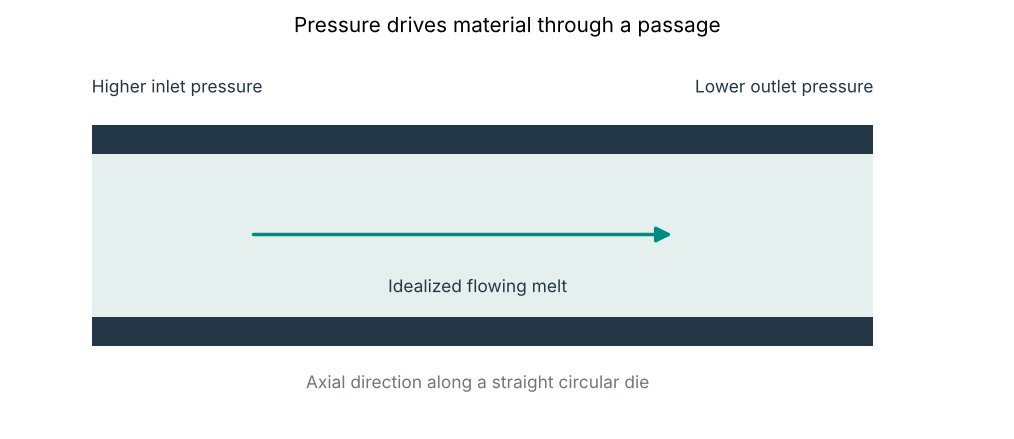

In [3]:
# Draw a labeled longitudinal view rather than assuming students know a die.
fig, ax = plt.subplots(figsize=(8.0, 3.4), layout="constrained")
# Outline the upper solid wall as a dark rectangular band.
ax.add_patch(Rectangle((0.08, 0.71), 0.79, 0.075, facecolor=colors["ink"]))
# Outline the matching lower solid wall around the flow passage.
ax.add_patch(Rectangle((0.08, 0.21), 0.79, 0.075, facecolor=colors["ink"]))
# Fill the space containing the model melt with a restrained color.
ax.add_patch(Rectangle((0.08, 0.285), 0.79, 0.425, facecolor="#E5F0EE", edgecolor="none"))
# Show the flow direction using an arrow along the center of the passage.
ax.add_patch(FancyArrowPatch((0.24, 0.50), (0.67, 0.50), arrowstyle="-|>", mutation_scale=18, lw=2, color=colors["teal"]))
# Identify inlet and outlet relative to the flow direction.
ax.text(0.08, 0.87, "Higher inlet pressure", color=colors["ink"], ha="left")
# Identify the lower-pressure side as the flow destination.
ax.text(0.87, 0.87, "Lower outlet pressure", color=colors["ink"], ha="right")
# Give the fluid region a readable label separate from the arrow.
ax.text(0.47, 0.35, "Idealized flowing melt", color=colors["ink"], ha="center")
# Name the direction along the die without pretending the sketch is to scale.
ax.text(0.47, 0.10, "Axial direction along a straight circular die", color=colors["grey"], ha="center")
# Use a schematic coordinate box rather than numerical axes.
ax.set(xlim=(0, 1), ylim=(0, 1), title="Pressure drives material through a passage")
# Hide numerical ticks because this panel describes topology, not measurements.
ax.axis("off")
# Save and display the introductory original schematic.
finish_figure(fig, "01_circular_die_schematic")

**Figure 1.** Longitudinal sketch of a circular passage. We model the melt already inside the die. The diagram does not imply that melting, heating, cooling, die-entry losses, or an actual extruder have been modeled.

## 2. Viscosity can depend on how fast we deform the melt

Slide a flat layer of material past a neighboring layer: a large difference in their speeds over a small distance means a large **shear rate** $\dot\gamma$. A simple Newtonian liquid has constant viscosity, so $\tau=\eta\dot\gamma$ is a straight line. A common *shear-thinning* model gives a smaller viscosity at a larger shear rate. Many polymer processing flows show such behavior, but a specific melt must be measured before its parameters are known.

The **Carreau–Yasuda** law used in the 2022 paper is

$$\eta(\dot\gamma)=\eta_\infty+(\eta_0-\eta_\infty)
\left[1+(\lambda\dot\gamma)^a\right]^{(n-1)/a}.$$

$\eta_0$ and $\eta_\infty$ (Pa·s) are low- and high-shear limiting viscosities; $\lambda$ (s) sets the shear-rate scale $\lambda\dot\gamma\sim1$ for the transition; $a>0$ controls its breadth; and $0<n<1$ describes shear thinning. Since s times 1/s is dimensionless, the power is meaningful. The paper's illustrative parameter set is $\eta_0=1400$ Pa·s, $\eta_\infty=0$ Pa·s, $\lambda=1.6$ s, $n=0.2$, $a=1.25$. **Zero $\eta_\infty$ is a model limit, not a claim that a real melt has literally zero high-rate viscosity.**

**Predict:** at $\dot\gamma=0$, what is $\eta$? At $\lambda\dot\gamma\gg1$, should the viscosity be larger or smaller for $n=0.2$? We start by implementing exactly the published expression and checking its limits.

In [4]:
# Store the paper's illustrative zero-shear viscosity in pascal-seconds.
fluid = {"eta0_pa_s": 1400.0, "eta_inf_pa_s": 0.0, "lambda_s": 1.60, "n": 0.20, "a": 1.25}
# Define the viscosity model for a scalar or an array of nonnegative shear rates.
def viscosity_pa_s(rate_s_inv, material):
    '''Return Carreau–Yasuda viscosity in Pa·s for shear rate in 1/s.'''
    # Convert an input number or list to an array compatible with NumPy powers.
    rate = np.asarray(rate_s_inv, dtype=float)
    # Form the unitless product that marks the material-law transition.
    dimensionless_rate = material["lambda_s"] * rate
    # Read the unitless exponent so the meaning of the power remains visible.
    transition_power = (material["n"] - 1.0) / material["a"]
    # Evaluate the published five-parameter viscosity relation.
    return material["eta_inf_pa_s"] + (material["eta0_pa_s"] - material["eta_inf_pa_s"]) * (1.0 + dimensionless_rate**material["a"]) ** transition_power

In [5]:
# Evaluate a few shear rates to see the trend before producing a smooth plot.
trial_rates_s_inv = np.array([0.0, 0.1, 1.0, 10.0, 100.0])
# Calculate one viscosity per selected rate; the two arrays have matching shape.
trial_viscosities_pa_s = viscosity_pa_s(trial_rates_s_inv, fluid)
# Present both columns to connect numerical outputs to physical units.
for rate, eta in zip(trial_rates_s_inv, trial_viscosities_pa_s):
    # Explain the computed decrease in an ordinary numerical table.
    print(f"Shear rate {rate:6.1f} 1/s  ->  viscosity {eta:9.2f} Pa·s")
# Recover the low-rate limit from the first sample without extrapolation.
assert np.isclose(trial_viscosities_pa_s[0], fluid["eta0_pa_s"])
# Check the expected decreasing sequence for this shear-thinning parameter set.
assert np.all(np.diff(trial_viscosities_pa_s) < 0.0)

Shear rate    0.0 1/s  ->  viscosity   1400.00 Pa·s
Shear rate    0.1 1/s  ->  viscosity   1316.24 Pa·s
Shear rate    1.0 1/s  ->  viscosity    724.43 Pa·s
Shear rate   10.0 1/s  ->  viscosity    149.38 Pa·s
Shear rate  100.0 1/s  ->  viscosity     24.12 Pa·s


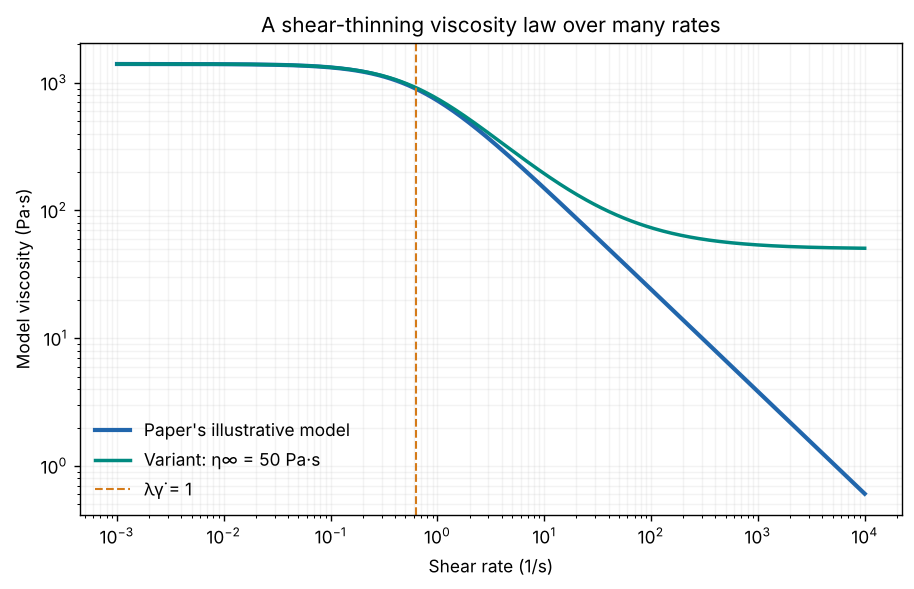

In [6]:
# Choose a logarithmic shear-rate grid that shows slow and fast deformation.
rate_grid_s_inv = np.logspace(-3.0, 4.0, 501)
# Evaluate the published illustrative fluid on every grid point.
eta_curve_pa_s = viscosity_pa_s(rate_grid_s_inv, fluid)
# Make a finite-plateau variant only to explain what eta-infinity means.
finite_plateau_fluid = {**fluid, "eta_inf_pa_s": 50.0}
# Evaluate that separate teaching variant over the same rates.
eta_finite_pa_s = viscosity_pa_s(rate_grid_s_inv, finite_plateau_fluid)
# Set up a compact publication-style log-log plot of the viscosity law.
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
# Draw the paper's example without confusing its zero limiting viscosity with data.
ax.loglog(rate_grid_s_inv, eta_curve_pa_s, color=colors["blue"], lw=2.4, label="Paper's illustrative model")
# Draw the labeled teaching variant with a nonzero high-rate plateau.
ax.loglog(rate_grid_s_inv, eta_finite_pa_s, color=colors["teal"], lw=2.0, label="Variant: η∞ = 50 Pa·s")
# Mark the unitless transition point lambda times rate = 1.
ax.axvline(1.0 / fluid["lambda_s"], ls="--", lw=1.2, color=colors["orange"], label="λγ̇ = 1")
# Label physical axes and avoid implying that either curve is measured data.
ax.set(xlabel="Shear rate (1/s)", ylabel="Model viscosity (Pa·s)", title="A shear-thinning viscosity law over many rates")
# Keep logarithmic grid lines faint so both curves remain distinct.
ax.grid(alpha=0.15, which="both")
# Locate a restrained legend in the uncluttered corner of the plot.
ax.legend(frameon=False, loc="lower left")
# Save and show the original viscosity comparison.
finish_figure(fig, "02_viscosity_vs_shear_rate")

**Figure 2.** The model's viscosity decreases with shear rate. The teal curve is a *different hypothetical parameter set* that illustrates a nonzero limiting plateau; neither curve is a measurement of a specified polymer grade. On a logarithmic axis, equal horizontal distances represent equal **ratios**, not equal additions.

## 3. Pressure sets the stress, then the material law sets the shear rate

Why is the wall special? Imagine a cylinder of melt of radius $r$ and length $L$ inside the passage. The pressure force on its end is $\pi r^2\Delta p$. The opposing force on its curved side is $2\pi r L\tau(r)$. Balancing these forces gives

$$\pi r^2\Delta p=2\pi rL\tau(r),\qquad
\boxed{\tau(r)=\frac{Gr}{2}},\qquad \tau_w=\frac{GR}{2}.$$

This is the 2022 paper's Eqs. (3)–(4). The stress is zero at the center and largest at the wall. At every $r$, the material law must also satisfy $\tau(r)=\eta(\dot\gamma)\dot\gamma$. Together these determine the local shear rate. They do **not** tell us that viscosity itself increases with stress; the material law decides its response.

**Predict by hand:** for $G=0.6$ MPa/m and $R=0.010$ m, what wall stress (Pa) follows? Then check that Pa/m multiplied by m gives Pa.

In [7]:
# Choose the pressure gradient used for the 2022 paper's velocity profile.
gradient_pa_m = 0.6e6
# Convert pressure loss per metre into wall shear stress using the force balance.
wall_stress_pa = gradient_pa_m * radius_m / 2.0
# Evaluate the matching pressure loss over a 1 m horizontal model segment.
one_metre_loss_pa = gradient_pa_m * 1.0
# Print the wall stress and one-metre pressure drop with separate units.
print(f"Wall shear stress = {wall_stress_pa:.0f} Pa; pressure loss over 1 m = {one_metre_loss_pa / 1e6:.2f} MPa")
# Independently compare pressure and side-shear forces for a 1 m fluid cylinder.
assert np.isclose(np.pi * radius_m**2 * one_metre_loss_pa, 2.0 * np.pi * radius_m * 1.0 * wall_stress_pa)

Wall shear stress = 3000 Pa; pressure loss over 1 m = 0.60 MPa


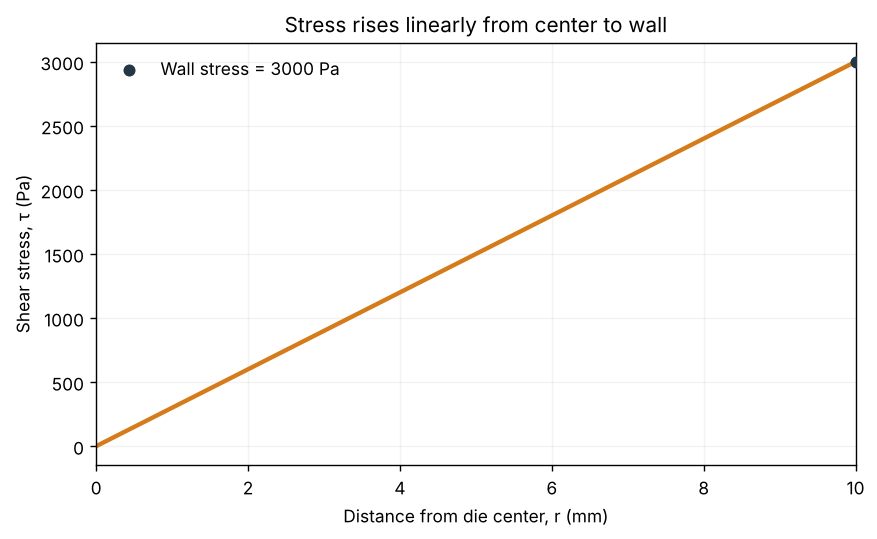

In [8]:
# Sample radial positions from the center of the die to its inside wall.
stress_r_m = np.linspace(0.0, radius_m, 401)
# Apply the linear force balance to all sampled radii.
radial_stress_pa = gradient_pa_m * stress_r_m / 2.0
# Prepare a plot that makes the center-to-wall change explicit.
fig, ax = plt.subplots(figsize=(6.9, 4.2), layout="constrained")
# Draw the predicted stress profile using distance in millimetres.
ax.plot(stress_r_m * 1000.0, radial_stress_pa, color=colors["orange"], lw=2.5)
# Mark the hand-computed wall stress without extra chart clutter.
ax.scatter([radius_m * 1000.0], [wall_stress_pa], color=colors["ink"], s=35, zorder=3, label="Wall stress = 3000 Pa")
# Label the geometry, stress, and units; zero is the centerline.
ax.set(xlabel="Distance from die center, r (mm)", ylabel="Shear stress, τ (Pa)", title="Stress rises linearly from center to wall", xlim=(0, radius_m * 1000.0))
# Add a light grid for reading the radius-dependent physical quantity.
ax.grid(alpha=0.16)
# Explain the point at the wall in a restrained legend.
ax.legend(frameon=False, loc="upper left")
# Export and display the force-balance result.
finish_figure(fig, "03_stress_from_pressure")

**Figure 3.** Pressure sets a simple stress distribution. Turning stress into speed is harder because the viscosity depends on the unknown local shear rate.

## 4. How do we turn stress into shear rate?

Define the **flow curve** $\tau(\dot\gamma)=\eta(\dot\gamma)\dot\gamma$. To find the rate at a given stress, we solve the one-variable equation $\tau(\dot\gamma)=\tau_{\rm target}$. For the stated positive parameter range, stress rises with shear rate, even though viscosity decreases. We can therefore use **bisection**: find a lower and upper shear rate on opposite sides of the target stress, repeatedly halve the interval, and keep the appropriate half. A list of radii can be processed as a NumPy array, so the same loop updates many brackets at once.

For completeness, the later preprint proves that $d\tau/d\dot\gamma$ is positive for $a>0$, $n>0$, and $\eta_0>\eta_\infty\ge0$. If $X=(\lambda\dot\gamma)^a$, then

$$\frac{d\tau}{d\dot\gamma}=\eta_\infty+(\eta_0-\eta_\infty)(1+X)^{(n-1)/a-1}(1+nX)>0.$$

This is an optional mathematical assurance; students only need to understand that a stress value selects one shear rate in our model.

In [9]:
# Convert a trial shear rate into the stress needed to maintain it.
def flow_stress_pa(rate_s_inv, material):
    '''Return shear stress in Pa from viscosity times shear rate.'''
    # Multiply each rate by its rate-dependent viscosity in Pa·s.
    return viscosity_pa_s(rate_s_inv, material) * np.asarray(rate_s_inv, dtype=float)

# Calculate the positive derivative of stress for an independent monotonicity check.
def flow_slope_pa_s(rate_s_inv, material):
    '''Return the Carreau–Yasuda stress slope dτ/dγ̇ in Pa·s.'''
    # Accept a scalar or array of nonnegative shear rates.
    rate = np.asarray(rate_s_inv, dtype=float)
    # Form the nonnegative unitless power X of lambda times rate.
    x_value = (material["lambda_s"] * rate) ** material["a"]
    # Read the power-law exponent so the positive bracket is easy to recognize.
    transition_power = (material["n"] - 1.0) / material["a"]
    # Evaluate the derivative given in the later preprint's Eq. (11), in SI units.
    return material["eta_inf_pa_s"] + (material["eta0_pa_s"] - material["eta_inf_pa_s"]) * (1.0 + x_value) ** (transition_power - 1.0) * (1.0 + material["n"] * x_value)

# Check the derivative remains positive over the displayed rate range.
assert np.all(flow_slope_pa_s(rate_grid_s_inv, fluid) > 0.0)

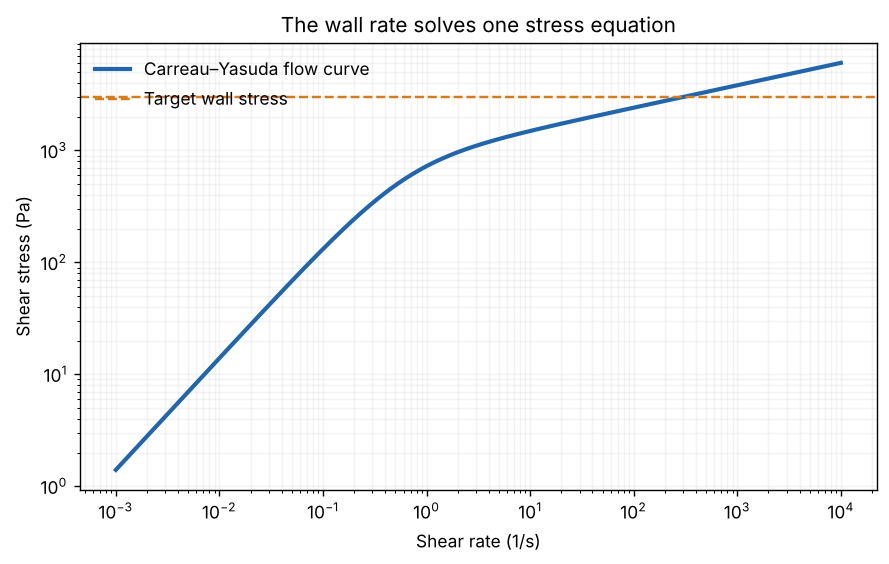

In [10]:
# Plot the stress law, whose monotonicity makes the inverse problem unambiguous.
fig, ax = plt.subplots(figsize=(7.0, 4.4), layout="constrained")
# Draw stress versus rate on logarithmic axes to cover the wide range fairly.
ax.loglog(rate_grid_s_inv, flow_stress_pa(rate_grid_s_inv, fluid), color=colors["blue"], lw=2.4, label="Carreau–Yasuda flow curve")
# Mark the stress fixed by the sample die's pressure gradient and radius.
ax.axhline(wall_stress_pa, color=colors["orange"], ls="--", lw=1.4, label="Target wall stress")
# Explain what will be found at the intersection of the two curves.
ax.set(xlabel="Shear rate (1/s)", ylabel="Shear stress (Pa)", title="The wall rate solves one stress equation")
# Keep log-grid guides visible without obscuring the intersection.
ax.grid(alpha=0.15, which="both")
# Place a legend that separates the horizontal target from the material law.
ax.legend(frameon=False, loc="upper left")
# Export the original picture of the scalar inverse problem.
finish_figure(fig, "04_wall_shear_rate_intersection")

In [11]:
# Implement bracketed bisection for a scalar stress or a vector of stresses.
def shear_rate_from_stress_s_inv(stress_pa_value, material):
    '''Invert τ=η(γ̇)γ̇ with one vectorized bisection loop.'''
    # Convert input stresses into NumPy form while preserving scalar compatibility.
    target = np.asarray(stress_pa_value, dtype=float)
    # Since viscosity never exceeds eta0, target/eta0 is a safe lower rate.
    lower = target / material["eta0_pa_s"]
    # Start upper rates at at least 1/s to avoid a zero-width bracket at the center.
    upper = np.maximum(lower, 1.0)
    # Permit a wide rate bracket when n is small and the trial stress is large.
    for _ in range(160):
        # Double only entries that still lie below their required stress.
        upper = np.where(flow_stress_pa(upper, material) < target, 2.0 * upper, upper)
    # Stop explicitly if an extreme input escaped the planned bracketing range.
    assert np.all(flow_stress_pa(upper, material) >= target)
    # Repeatedly halve all brackets to locate one rate per target stress.
    for _ in range(60):
        # Test the rate halfway between each lower and upper endpoint.
        midpoint = (lower + upper) / 2.0
        # Keep the midpoint as the new lower bound when its stress is too small.
        lower = np.where(flow_stress_pa(midpoint, material) < target, midpoint, lower)
        # Otherwise keep the midpoint as the new upper bound.
        upper = np.where(flow_stress_pa(midpoint, material) >= target, midpoint, upper)
    # Make the zero-stress centerline exactly zero rather than machine epsilon.
    return np.where(target == 0.0, 0.0, (lower + upper) / 2.0)

In [12]:
# Find the wall rate required to generate the paper's illustrative wall stress.
wall_rate_s_inv = float(shear_rate_from_stress_s_inv(wall_stress_pa, fluid))
# Calculate the viscosity at that solved rate rather than assuming eta0.
wall_viscosity_pa_s = float(viscosity_pa_s(wall_rate_s_inv, fluid))
# Substitute the rate back into the original stress equation for a residual check.
wall_residual_pa = float(flow_stress_pa(wall_rate_s_inv, fluid) - wall_stress_pa)
# Compare with the repository's example value of about 296.5 inverse seconds.
print(f"γ̇_wall = {wall_rate_s_inv:.3f} 1/s; η_wall = {wall_viscosity_pa_s:.2f} Pa·s; stress residual = {wall_residual_pa:.2e} Pa")
# Demand a small *relative* residual so the check is meaningful at other stresses.
assert abs(wall_residual_pa) / wall_stress_pa < 1e-12
# Verify the published example rate within a stated three-significant-digit tolerance.
assert np.isclose(wall_rate_s_inv, 296.5, rtol=2e-3)

γ̇_wall = 296.533 1/s; η_wall = 10.12 Pa·s; stress residual = 4.55e-13 Pa


## 5. Turn local shear into a velocity profile

The die wall is stationary in this idealized model: $u(R)=0$, called **no slip**. As we move *inward*, the speed rises by the sum of small local speed changes. A thin interval of width $\Delta r$ contributes approximately $\dot\gamma\,\Delta r$ to speed (units: 1/s times m = m/s). Thus

$$u(r)=\int_r^R\dot\gamma(s)\,ds.$$

We will compute shear rate at many radii and add trapezoid-shaped contributions. The second integration adds circular rings of area $2\pi r\,dr$ to obtain $Q=2\pi\int_0^R u(r)r\,dr$. In a Newtonian liquid, this produces a parabola. **Predict:** where is melt speed highest, and what must it be at the wall?

In [13]:
# Construct the radial shear and velocity profile for one material and die.
def pipe_profile(pressure_gradient_pa_m, die_radius_m, material, points=2001):
    '''Return radius, stress, rate, viscosity, speed, Q, and averages in SI units.'''
    # Include both the zero-stress center and the stationary outer wall.
    radial_m = np.linspace(0.0, die_radius_m, points)
    # Use the circular-tube momentum balance to find stress at each radius.
    stress_pa = pressure_gradient_pa_m * radial_m / 2.0
    # Invert the material's nonlinear stress curve at all radii together.
    rate_s_inv = shear_rate_from_stress_s_inv(stress_pa, material)
    # Calculate a local viscosity for every obtained shear rate.
    eta_pa_s = viscosity_pa_s(rate_s_inv, material)
    # Find each small outward radial interval, measured in metres.
    widths_m = np.diff(radial_m)
    # Approximate each shear-rate integral by a trapezoid, in metres per second.
    speed_steps_m_s = 0.5 * (rate_s_inv[:-1] + rate_s_inv[1:]) * widths_m
    # Accumulate speed changes outward from the center on the same array grid.
    outward_running_m_s = np.concatenate(([0.0], np.cumsum(speed_steps_m_s)))
    # Subtract the outward sum from the total to satisfy zero speed at the wall.
    speed_m_s = outward_running_m_s[-1] - outward_running_m_s
    # Integrate the speeds of circular rings to obtain cubic metres per second.
    q_m3_s = 2.0 * np.pi * np.trapezoid(speed_m_s * radial_m, radial_m)
    # Divide by the circular area for the speed averaged over the cross-section.
    average_speed_m_s = q_m3_s / (np.pi * die_radius_m**2)
    # Name all outputs to keep subsequent notebook calculations readable.
    return {"r_m": radial_m, "stress_pa": stress_pa, "rate_s_inv": rate_s_inv, "eta_pa_s": eta_pa_s, "u_m_s": speed_m_s, "Q_m3_s": q_m3_s, "u_avg_m_s": average_speed_m_s, "u_max_m_s": speed_m_s[0]}

In [14]:
# Compute the published illustrative flow at 0.6 MPa/m and 10 mm radius.
example = pipe_profile(gradient_pa_m, radius_m, fluid)
# Convert the computed volume rate from m³/s into litres per minute.
example_q_l_min = example["Q_m3_s"] * 60000.0
# Print the wall and central speeds beside the throughput in familiar units.
print(f"Center speed = {example['u_max_m_s']:.4f} m/s; average speed = {example['u_avg_m_s']:.4f} m/s")
# State the delivery rate both in SI and in a processing-friendly unit.
print(f"Q = {example['Q_m3_s']:.8f} m³/s = {example_q_l_min:.3f} L/min")
# Confirm speed is zero at the wall and cannot increase while moving outward.
assert np.isclose(example["u_m_s"][-1], 0.0, atol=1e-12)
# Check that the maximum for this monotone profile lies at its centerline.
assert np.all(np.diff(example["u_m_s"]) <= 1e-12)
# Compare with the published repository's roughly 0.372 m/s mean-speed example.
assert np.isclose(example["u_avg_m_s"], 0.372, rtol=2e-3)

Center speed = 0.5000 m/s; average speed = 0.3722 m/s
Q = 0.00011694 m³/s = 7.016 L/min


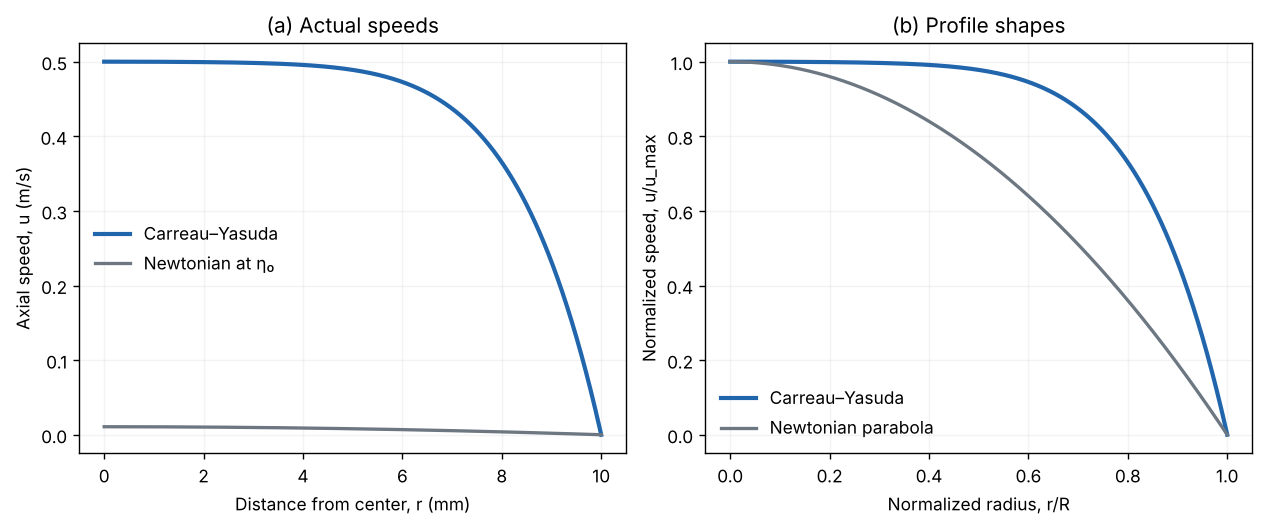

In [15]:
# Calculate the constant-eta0 Newtonian speed at the same radius and pressure.
newtonian_center_m_s = gradient_pa_m * radius_m**2 / (4.0 * fluid["eta0_pa_s"])
# Evaluate its classic parabolic profile on the same radial grid.
newtonian_u_m_s = newtonian_center_m_s * (1.0 - (example["r_m"] / radius_m) ** 2)
# Set up actual-speed and normalized-shape panels with distinct meanings.
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.1), layout="constrained")
# Show the model melt's actual local speed across the tube.
axes[0].plot(1000.0 * example["r_m"], example["u_m_s"], color=colors["blue"], lw=2.4, label="Carreau–Yasuda")
# Compare a Newtonian fluid kept at eta0 under the same pressure.
axes[0].plot(1000.0 * example["r_m"], newtonian_u_m_s, color=colors["grey"], lw=1.9, label="Newtonian at η₀")
# Compare *shapes* after dividing each profile by its own peak speed.
axes[1].plot(example["r_m"] / radius_m, example["u_m_s"] / example["u_max_m_s"], color=colors["blue"], lw=2.4, label="Carreau–Yasuda")
# Plot the exact parabolic Newtonian shape on the same unitless coordinates.
axes[1].plot(example["r_m"] / radius_m, newtonian_u_m_s / newtonian_center_m_s, color=colors["grey"], lw=1.9, label="Newtonian parabola")
# State physical units for the actual-speed comparison at left.
axes[0].set(xlabel="Distance from center, r (mm)", ylabel="Axial speed, u (m/s)", title="(a) Actual speeds")
# State the two normalized variables so shapes can be compared honestly.
axes[1].set(xlabel="Normalized radius, r/R", ylabel="Normalized speed, u/u_max", title="(b) Profile shapes")
# Use consistent, restrained legends and grids in the two panels.
for ax in axes:
    # Identify the two material models, even in a black-and-white printout.
    ax.legend(frameon=False)
    # Provide unobtrusive coordinate guides for the physical comparison.
    ax.grid(alpha=0.15)
# Export and embed the original velocity-profile comparison.
finish_figure(fig, "05_velocity_and_shape")

**Figure 5.** At the same pressure gradient, the model fluid flows faster than a Newtonian comparison held at $\eta_0$. The normalized panel compares **shapes**, not absolute speeds: the shear-thinning profile is flatter in its middle and steeper near the wall. The statement applies to these chosen model laws and conditions.

### See the same velocity profile across the circular opening

The previous plot showed speed on one center-to-wall line. A straight circular die has the same speed at every point with the same radius $r=\sqrt{x^2+y^2}$. We can rotate the computed line around the center to make a **3D velocity surface**: the horizontal coordinates locate a point in the cross-section, and the height is its **axial speed**, not the physical height or shape of the melt. The paper's example should make a dome with its peak at the center and zero speed all around the stationary wall. **Predict:** would changing only the viewing angle change the calculated throughput?

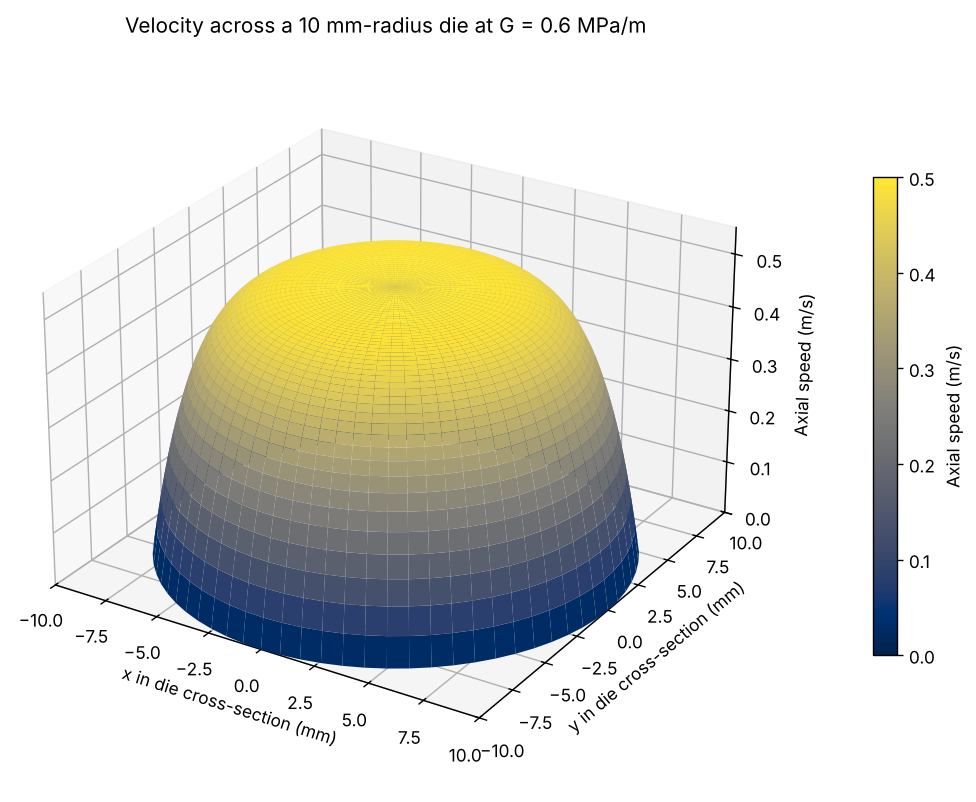

In [16]:
# Sample every twentieth radius to keep the 3D teaching plot lightweight.
dome_r_m = example["r_m"][::20]
# Carry the corresponding solved speeds without fitting a new surface law.
dome_u_m_s = example["u_m_s"][::20]
# Sample one full turn around the circular die, including the closing angle.
dome_theta_rad = np.linspace(0.0, 2.0 * np.pi, 73)
# Repeat radii across angles to describe a circular cross-section.
dome_radius_grid_m, dome_angle_grid_rad = np.meshgrid(dome_r_m, dome_theta_rad, indexing="ij")
# Convert radial coordinates to a horizontal x position in millimetres.
dome_x_mm = 1000.0 * dome_radius_grid_m * np.cos(dome_angle_grid_rad)
# Convert radial coordinates to the matching horizontal y position.
dome_y_mm = 1000.0 * dome_radius_grid_m * np.sin(dome_angle_grid_rad)
# Give every point on a circle the same axial speed in metres per second.
dome_z_m_s = np.repeat(dome_u_m_s[:, None], dome_theta_rad.size, axis=1)
# Confirm that rotation preserves the center speed and no-slip wall speed.
assert np.allclose(dome_z_m_s[0], example["u_max_m_s"]) and np.allclose(dome_z_m_s[-1], 0.0)
# Create a wide layout so the full surface and its colorbar remain legible.
dome_fig = plt.figure(figsize=(8.4, 6.3), layout="constrained")
# Use Matplotlib's 3D axes to draw speed above the cross-sectional plane.
dome_ax = dome_fig.add_subplot(111, projection="3d")
# Shade by the actual speed while keeping an explicit common color scale.
dome_surface = dome_ax.plot_surface(dome_x_mm, dome_y_mm, dome_z_m_s, cmap="cividis", vmin=0.0, vmax=example["u_max_m_s"], rstride=2, cstride=1, linewidth=0.0, antialiased=True, shade=False)
# Label positions in millimetres and the vertical *speed* in m/s.
dome_ax.set(xlabel="x in die cross-section (mm)", ylabel="y in die cross-section (mm)", zlabel="Axial speed (m/s)", title="Velocity across a 10 mm-radius die at G = 0.6 MPa/m")
# Use symmetric horizontal limits so the plotted opening remains circular.
dome_ax.set(xlim=(-10.0, 10.0), ylim=(-10.0, 10.0), zlim=(0.0, 0.55))
# Choose an oblique view that reveals both the wall and the central peak.
dome_ax.view_init(elev=26, azim=-58)
# Set a readable display aspect without changing any physical quantity.
dome_ax.set_box_aspect((1.0, 1.0, 0.65))
# Explain the surface colors using a separate scale with real speed units.
dome_fig.colorbar(dome_surface, ax=dome_ax, shrink=0.64, pad=0.11, label="Axial speed (m/s)")
# Export SVG and 300 dpi PNG and embed this original 3D figure.
finish_figure(dome_fig, "05a_velocity_dome_3d")

**Figure 5a.** The 3D dome is another view of the *same* $u(r)$ values used in Figure 5; rotation around the center does not add a new flow calculation. Its vertical coordinate and color both represent axial speed. Equal-speed circles arise from the assumed rotational symmetry.

### Animate a change in pressure, while keeping the display scale fixed

The [research repository's animation](https://github.com/ktwyw/carreau-yasuda-pipe-flow/blob/main/figures/dome_animation_normalized.gif) and its [Python source](https://github.com/ktwyw/carreau-yasuda-pipe-flow/blob/main/scripts/dome_animation.py) inspired this new, self-contained cell. We solve the existing model at 24 pressure gradients from $0.02$ to $1.0$ MPa/m. Each frame divides speed by *that frame's* center speed $u_{\max}$; the horizontal distance uses $R$. The $0$–$1$ vertical scale stays fixed so a changing dome shape can be compared fairly. The frame label also gives the pressure gradient and the dimensionless ratio $u_{\max}/\bar u$. **Predict:** as pressure rises and the material shear thins, will this ratio move toward or away from the Newtonian value 2?

The frames are different **steady model conditions**, not time steps in a transient flow. Normalizing by each frame's $u_{\max}$ hides the rise in actual speed; refer to Figure 7 to see the corresponding growth in throughput. The animation cell uses Pillow via Matplotlib's `PillowWriter` and saves a looping GIF to `figures_polymer_melt/`. It also embeds that GIF below the cell for offline reading.

Center/mean ratio: 1.987 at 0.02 MPa/m → 1.334 at 1.0 MPa/m


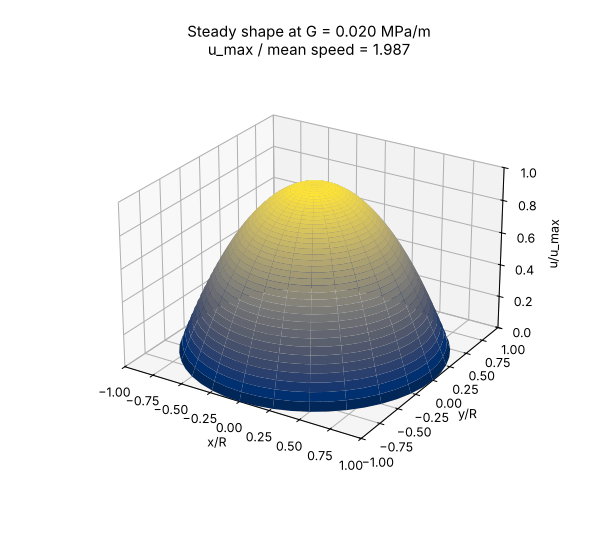

In [17]:
# Import Matplotlib's small GIF animation tools for an offline notebook.
from matplotlib.animation import FuncAnimation, PillowWriter
# Import notebook display tools so the completed GIF appears below this cell.
from IPython.display import Image, display
# Sample pressure gradients logarithmically to show both early and late changes.
animation_gradients_pa_m = np.geomspace(0.02e6, 1.0e6, 24)
# Solve each pressure condition once; these are separate steady profiles.
animation_profiles = [pipe_profile(g, radius_m, fluid, points=121) for g in animation_gradients_pa_m]
# Scale radial distance by the unchanged die radius for every frame.
animation_r_over_R = animation_profiles[0]["r_m"] / radius_m
# Sample a full circle with enough angular points for a smooth small GIF.
animation_theta_rad = np.linspace(0.0, 2.0 * np.pi, 49)
# Build one horizontal mesh shared by all of the pressure conditions.
animation_radius_grid, animation_angle_grid = np.meshgrid(animation_r_over_R, animation_theta_rad, indexing="ij")
# Locate each point horizontally on a normalized unit-radius disk.
animation_x = animation_radius_grid * np.cos(animation_angle_grid)
# Complete the circular coordinate pair for the unchanging die geometry.
animation_y = animation_radius_grid * np.sin(animation_angle_grid)
# Check that normalizing a speed cannot change the stationary wall.
assert all(np.isclose(profile["u_m_s"][-1], 0.0) for profile in animation_profiles)
# Compare the early and late center-to-mean ratios as a physical check.
animation_ratios = [profile["u_max_m_s"] / profile["u_avg_m_s"] for profile in animation_profiles]
# Show the numerical trend in addition to the visual changes in the dome.
print(f"Center/mean ratio: {animation_ratios[0]:.3f} at 0.02 MPa/m → {animation_ratios[-1]:.3f} at 1.0 MPa/m")
# Check the trend predicted for this illustrative shear-thinning model.
assert animation_ratios[-1] < animation_ratios[0]
# Create a single 3D figure whose same axes are redrawn for each frame.
animation_fig = plt.figure(figsize=(6.7, 6.0))
# Keep the horizontal and vertical viewing geometry fixed across frames.
animation_ax = animation_fig.add_subplot(111, projection="3d")
# Define how a chosen pressure case is drawn on that shared 3D canvas.
def draw_dome_frame(frame_index):
    '''Draw one normalized steady velocity surface for the GIF.'''
    # Clear only the animation axes to remove the previous case.
    animation_ax.clear()
    # Read the already computed velocity and pressure for this frame.
    frame_profile = animation_profiles[frame_index]
    # Scale each speed by its own center value to compare shape alone.
    frame_u_over_umax = frame_profile["u_m_s"] / frame_profile["u_max_m_s"]
    # Repeat the radial shape for all angles without changing physics.
    frame_height = np.repeat(frame_u_over_umax[:, None], animation_theta_rad.size, axis=1)
    # Draw the normalized surface with the same 0-to-1 color scale.
    frame_surface = animation_ax.plot_surface(animation_x, animation_y, frame_height, cmap="cividis", vmin=0.0, vmax=1.0, rstride=3, cstride=2, linewidth=0.0, antialiased=True, shade=False)
    # Set fixed limits so changes in shape are not caused by rescaling.
    animation_ax.set(xlim=(-1.0, 1.0), ylim=(-1.0, 1.0), zlim=(0.0, 1.0), xlabel="x/R", ylabel="y/R", zlabel="u/u_max")
    # Identify the pressure and speed-shape ratio without a time label.
    animation_ax.set_title(f"Steady shape at G = {animation_gradients_pa_m[frame_index]/1e6:.3f} MPa/m\nu_max / mean speed = {animation_ratios[frame_index]:.3f}", pad=8)
    # Preserve the same camera location and displayed aspect each frame.
    animation_ax.view_init(elev=25, azim=-58)
    # Set display proportions consistently as the vertical shape changes.
    animation_ax.set_box_aspect((1.0, 1.0, 0.65))
    # Return the new artist for Matplotlib's animation interface.
    return (frame_surface,)
# Visit the 24 pressure states in order and loop on notebook playback.
dome_animation = FuncAnimation(animation_fig, draw_dome_frame, frames=len(animation_profiles), interval=170, repeat=True, blit=False)
# Give the reusable GIF an explicit name beside the other figure exports.
dome_gif_path = figure_dir / "05b_velocity_dome_shape_sweep.gif"
# Render the animation without a video encoder or network connection.
dome_animation.save(dome_gif_path, writer=PillowWriter(fps=6), dpi=90)
# Close the Matplotlib canvas once its 24 GIF frames are safely written.
plt.close(animation_fig)
# Embed the GIF bytes in the executed notebook for independent reading.
display(Image(filename=str(dome_gif_path)))

**Animation 1.** Each looping frame shows a different pressure gradient in the same model and die. A flatter dome means more of the cross-section moves close to the center speed; the center-to-mean ratio falls. Because height is $u/u_{\max}$, this animation shows **shape** rather than actual speed or material travelling in time. Try pausing near the first and last frames and compare their ratios with the two-dimensional Figure 8.

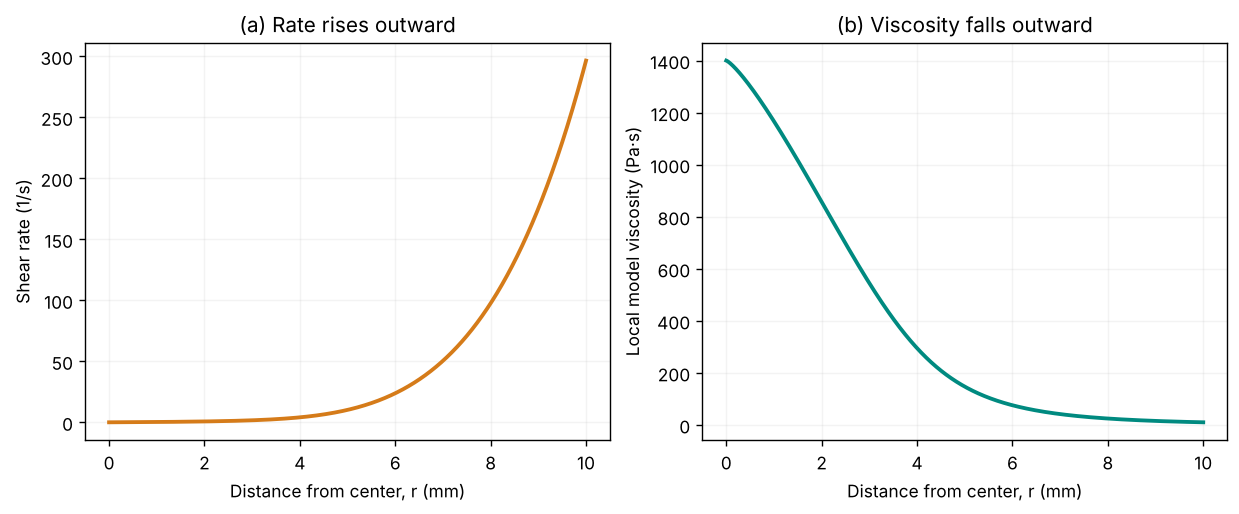

In [18]:
# Arrange local rate and viscosity in different panels to keep their units clear.
fig, axes = plt.subplots(1, 2, figsize=(9.8, 4.0), layout="constrained")
# Show how the needed rate rises as the radial stress rises.
axes[0].plot(1000.0 * example["r_m"], example["rate_s_inv"], color=colors["orange"], lw=2.2)
# Show the associated drop in local viscosity toward the high-shear wall.
axes[1].plot(1000.0 * example["r_m"], example["eta_pa_s"], color=colors["teal"], lw=2.2)
# Label the first local material-response panel and its unit.
axes[0].set(xlabel="Distance from center, r (mm)", ylabel="Shear rate (1/s)", title="(a) Rate rises outward")
# Label the viscosity panel without calling a local value an average.
axes[1].set(xlabel="Distance from center, r (mm)", ylabel="Local model viscosity (Pa·s)", title="(b) Viscosity falls outward")
# Support reading the profiles while keeping all axes linear in this figure.
for ax in axes:
    # Use a faint grid across both material-response panels.
    ax.grid(alpha=0.15)
# Save and show the model's linked rate and viscosity profiles.
finish_figure(fig, "06_rate_and_viscosity_profiles")

**Figure 6.** The material is the same throughout this single-region model; its *local* apparent viscosity changes because the local shear rate changes. We have not introduced a different fluid at the wall.

## 6. Scientific checks that could catch a real mistake

There are at least three useful cross-checks. First, the wall stress computed from $GR/2$ must equal $\eta(\dot\gamma_w)\dot\gamma_w$. Second, the flow found by adding circular speed rings must agree with a different integral, $Q=\pi\int_0^R\dot\gamma(r)r^2dr$. Third, forcing $n=1$ makes $\eta=\eta_0$ everywhere, so our numerical result must match the Newtonian Hagen–Poiseuille formula $Q=\pi GR^4/(8\eta_0)$. The last check changes the material model in a controlled way rather than comparing two copies of the same code.

In [19]:
# Independently sum radius-squared-weighted local shear rates to obtain Q.
stress_integral_q_m3_s = np.pi * np.trapezoid(example["rate_s_inv"] * example["r_m"] ** 2, example["r_m"])
# Compute the difference from the original velocity-ring method.
two_route_relative_error = abs(stress_integral_q_m3_s - example["Q_m3_s"]) / example["Q_m3_s"]
# Report the discrepancy because integration is approximate on a finite grid.
print(f"Ring Q = {example['Q_m3_s']:.9e}; shear-rate Q = {stress_integral_q_m3_s:.9e} m³/s")
# Show a meaningful numerical agreement rather than only a qualitative check.
print(f"Relative difference between integrals = {two_route_relative_error:.2e}")
# Detect a missing pi, radius weight, or sign error in the flow calculation.
assert two_route_relative_error < 2e-6
# Compare the inferred wall rate against the separately solved wall equation.
assert np.isclose(example["rate_s_inv"][-1], wall_rate_s_inv, rtol=1e-12)

Ring Q = 1.169352667e-04; shear-rate Q = 1.169353831e-04 m³/s
Relative difference between integrals = 9.96e-07


In [20]:
# Make n=1 without changing the baseline viscosity in Pa·s.
constant_viscosity_fluid = {**fluid, "n": 1.0}
# Run the *same numerical pipe solver* with a constant-viscosity material law.
newtonian_profile = pipe_profile(gradient_pa_m, radius_m, constant_viscosity_fluid)
# Calculate the classical analytical pipe result without using that solver.
poiseuille_q_m3_s = np.pi * gradient_pa_m * radius_m**4 / (8.0 * fluid["eta0_pa_s"])
# Show both results in litres per minute so their agreement is clear.
print(f"Numerical constant-viscosity Q = {60000 * newtonian_profile['Q_m3_s']:.6f} L/min")
# Print the independent formula using the same display unit.
print(f"Classical Poiseuille Q = {60000 * poiseuille_q_m3_s:.6f} L/min")
# Allow only the small trapezoidal integration error expected on a 2001-node grid.
assert np.isclose(newtonian_profile["Q_m3_s"], poiseuille_q_m3_s, rtol=2e-6)
# Validate the classic ratio of center speed to area-average speed.
assert np.isclose(newtonian_profile["u_max_m_s"] / newtonian_profile["u_avg_m_s"], 2.0, rtol=2e-6)

Numerical constant-viscosity Q = 0.100980 L/min
Classical Poiseuille Q = 0.100980 L/min


In [21]:
# Inspect numerical refinement rather than guessing how many radial nodes suffice.
node_counts = [101, 401, 1601, 6401]
# Use the research paper's example conditions at every resolution.
grid_q_values = [pipe_profile(gradient_pa_m, radius_m, fluid, points=count)["Q_m3_s"] for count in node_counts]
# Use the finest calculation only as a numerical comparison target.
finest_q_m3_s = grid_q_values[-1]
# Show each numerical approximation beside its difference from the finest grid.
for count, trial_q in zip(node_counts, grid_q_values):
    # Explain convergence in the unit students have already used.
    print(f"{count:5d} radial points -> {trial_q * 60000:.6f} L/min; deviation from finest = {abs(trial_q / finest_q_m3_s - 1):.2e}")
# Demand that an intermediate grid agrees with the fine grid to useful precision.
assert abs(grid_q_values[2] / finest_q_m3_s - 1.0) < 5e-6

  101 radial points -> 7.016576 L/min; deviation from finest = 6.58e-05
  401 radial points -> 7.016144 L/min; deviation from finest = 4.10e-06
 1601 radial points -> 7.016117 L/min; deviation from finest = 2.41e-07
 6401 radial points -> 7.016115 L/min; deviation from finest = 0.00e+00


**Reading the checks:** the finite-grid results approach a stable value as the number of points grows. Agreement between distinct formulas and a known special case gives more confidence than merely generating an attractive graph. Convergence alone cannot establish that a real melt obeys the model.

## 7. Does more pressure deliver proportionally more melt?

For constant viscosity and fixed radius, $Q\propto G$. The Carreau–Yasuda material changes viscosity as the stress and shear rate rise, so the $Q$–$G$ relation can depart strongly from a straight proportional line. We will change $G$ over a stated range while holding **material parameters and radius fixed**, then compare with a constant-$\eta_0$ material on the same units. The observations apply to the model over the displayed range; an actual die could heat or slip at high rates.

In [22]:
# Sweep pressure gradients from 100 Pa/m to one million Pa/m on a log grid.
gradient_values_pa_m = np.logspace(2.0, 6.0, 41)
# Solve the same model independently at each sampled pressure gradient.
flow_results = [pipe_profile(g, radius_m, fluid, points=801) for g in gradient_values_pa_m]
# Collect the volume rates from the profile dictionaries in SI units.
flow_q_m3_s = np.array([item["Q_m3_s"] for item in flow_results])
# Collect the center-to-average-speed shape indicator for each profile.
speed_ratios = np.array([item["u_max_m_s"] / item["u_avg_m_s"] for item in flow_results])
# Calculate the constant-viscosity comparison with a separate closed formula.
constant_eta_q_m3_s = np.pi * gradient_values_pa_m * radius_m**4 / (8.0 * fluid["eta0_pa_s"])
# Check that increased pressure yields increased modeled flow throughout this sweep.
assert np.all(np.diff(flow_q_m3_s) > 0.0)

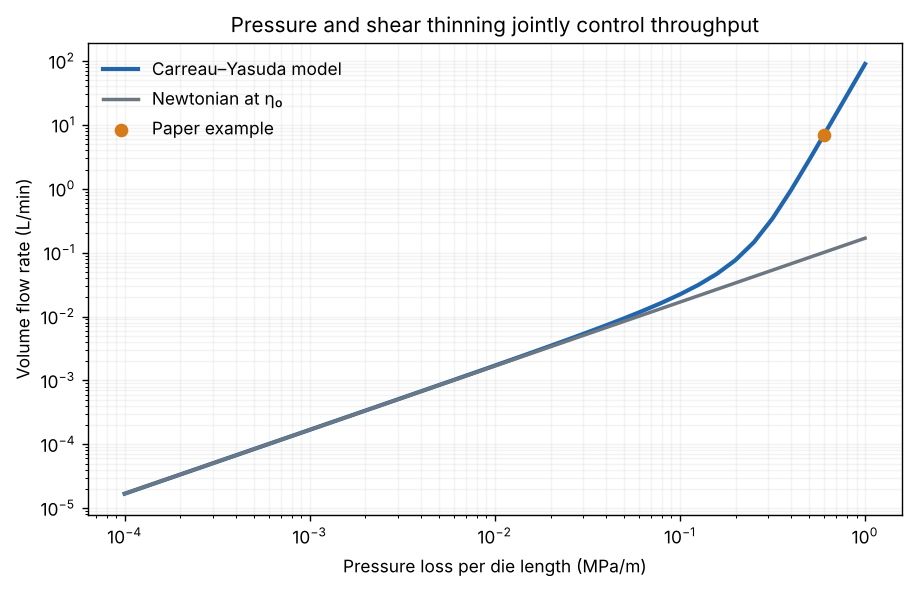

In [23]:
# Present flow response over wide pressure and throughput ranges without truncation.
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
# Draw the shear-thinning material's computed throughput in litres per minute.
ax.loglog(gradient_values_pa_m / 1e6, flow_q_m3_s * 60000.0, color=colors["blue"], lw=2.4, label="Carreau–Yasuda model")
# Draw the constant low-rate-viscosity reference for the same die geometry.
ax.loglog(gradient_values_pa_m / 1e6, constant_eta_q_m3_s * 60000.0, color=colors["grey"], lw=2.0, label="Newtonian at η₀")
# Identify the paper's example pressure as a point on the model curve.
ax.scatter([gradient_pa_m / 1e6], [example_q_l_min], color=colors["orange"], s=47, zorder=3, label="Paper example")
# State pressure and volume units; the axes are logarithmic over this wide range.
ax.set(xlabel="Pressure loss per die length (MPa/m)", ylabel="Volume flow rate (L/min)", title="Pressure and shear thinning jointly control throughput")
# Give readers ratios through a light log grid.
ax.grid(alpha=0.15, which="both")
# Separate the reference and the actual illustrative model in the legend.
ax.legend(frameon=False, loc="upper left")
# Save and embed the pressure–throughput comparison.
finish_figure(fig, "07_flow_vs_pressure")

**Figure 7.** On the same log-log axes, a Newtonian reference has slope one. The model curve changes slope as its viscosity drops with shear rate. The curves do not by themselves verify laminar flow, negligible heating, or a particular extruder operating envelope.

The shape ratio $u_{\max}/\bar u$ equals 2 for a Newtonian parabola. For the paper's $\eta_\infty=0$ fluid, the high-rate **power-law limit** is $(3n+1)/(n+1)$, about 1.33 when $n=0.2$. The calculation in the next cell shows how the profile becomes flatter as the material shear thins. A finite nonzero $\eta_\infty$ would eventually return to Newtonian-like behavior at sufficiently high shear; the 1.33 limit would then not apply.

Example u_max/u_avg = 1.3433; high-rate limit = 1.3333; Newtonian = 2.0000


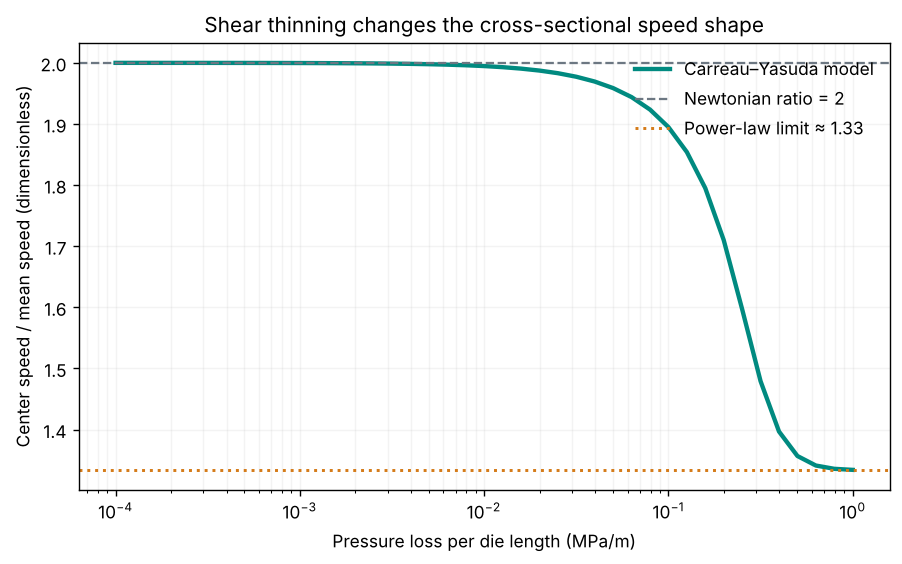

In [24]:
# Evaluate the model's high-shear power-law shape limit for this n.
high_rate_ratio = (3.0 * fluid["n"] + 1.0) / (fluid["n"] + 1.0)
# Calculate the example profile's observed ratio from two independently named speeds.
example_shape_ratio = example["u_max_m_s"] / example["u_avg_m_s"]
# Show how closely the example has approached, but not reached, the limit.
print(f"Example u_max/u_avg = {example_shape_ratio:.4f}; high-rate limit = {high_rate_ratio:.4f}; Newtonian = 2.0000")
# Draw the profile-shape change as the pressure gradient rises.
fig, ax = plt.subplots(figsize=(7.1, 4.4), layout="constrained")
# Display the computed ratio for every modeled pressure gradient.
ax.semilogx(gradient_values_pa_m / 1e6, speed_ratios, color=colors["teal"], lw=2.5, label="Carreau–Yasuda model")
# Mark the classical Newtonian shape limit from the independent result.
ax.axhline(2.0, color=colors["grey"], ls="--", lw=1.3, label="Newtonian ratio = 2")
# Mark the published model's high-rate power-law shape limit.
ax.axhline(high_rate_ratio, color=colors["orange"], ls=":", lw=1.7, label="Power-law limit ≈ 1.33")
# State that the ratio is dimensionless and the horizontal axis has pressure units.
ax.set(xlabel="Pressure loss per die length (MPa/m)", ylabel="Center speed / mean speed (dimensionless)", title="Shear thinning changes the cross-sectional speed shape")
# Make the two expected limits visually interpretable without heavy grid lines.
ax.grid(alpha=0.14, which="both")
# Locate the limit explanations in a compact legend.
ax.legend(frameon=False, loc="upper right")
# Save and display the physical profile-shape diagnostic.
finish_figure(fig, "08_profile_shape_with_pressure")

## 8. Which material parameter changes the result?

Engineers fit the five model parameters to measured material data. We will conduct a **one-at-a-time sensitivity experiment**: change one parameter, then compute the same pressure-driven die flow. This does not estimate real manufacturing uncertainty; it helps us understand what the equation says. At the present wall rate, $\lambda\dot\gamma$ is well above one. Raising $n$ from 0.2 to 0.4 reduces shear thinning; halving $\lambda$ moves the onset of shear thinning to a higher rate; doubling $\eta_0$ makes the material more viscous throughout this comparison. **Predict** whether each modification raises or lowers $Q$ before running the code.

In [25]:
# Give the original parameter set a clearly labeled reference entry.
material_variants = {"Reference": fluid}
# Change only n to make the viscosity decrease less quickly at high rates.
material_variants["n = 0.40"] = {**fluid, "n": 0.40}
# Change only lambda to move the onset of shear thinning to a higher rate.
material_variants["λ = 0.80 s"] = {**fluid, "lambda_s": 0.80}
# Change only eta0 to model a more viscous illustrative fluid.
material_variants["η₀ = 2800 Pa·s"] = {**fluid, "eta0_pa_s": 2800.0}
# Solve each material case at exactly the same pressure and radius.
variant_profiles = {name: pipe_profile(gradient_pa_m, radius_m, material, points=1201) for name, material in material_variants.items()}
# Display throughput and wall viscosity with the labels that describe each change.
for name, profile in variant_profiles.items():
    # Obtain the appropriate changed material instead of accidentally using fluid.
    material = material_variants[name]
    # Print a concrete processing quantity and a local property, with units.
    print(f"{name:18s}: Q = {60000 * profile['Q_m3_s']:7.3f} L/min; η_wall = {profile['eta_pa_s'][-1]:7.2f} Pa·s")
# Test the predicted direction for these particular parameter changes and state.
assert all(variant_profiles[name]["Q_m3_s"] < variant_profiles["Reference"]["Q_m3_s"] for name in list(material_variants)[1:])

Reference         : Q =   7.016 L/min; η_wall =   10.12 Pa·s
n = 0.40          : Q =   0.490 L/min; η_wall =  215.19 Pa·s
λ = 0.80 s        : Q =   0.553 L/min; η_wall =  147.23 Pa·s
η₀ = 2800 Pa·s    : Q =   0.277 L/min; η_wall =  294.46 Pa·s


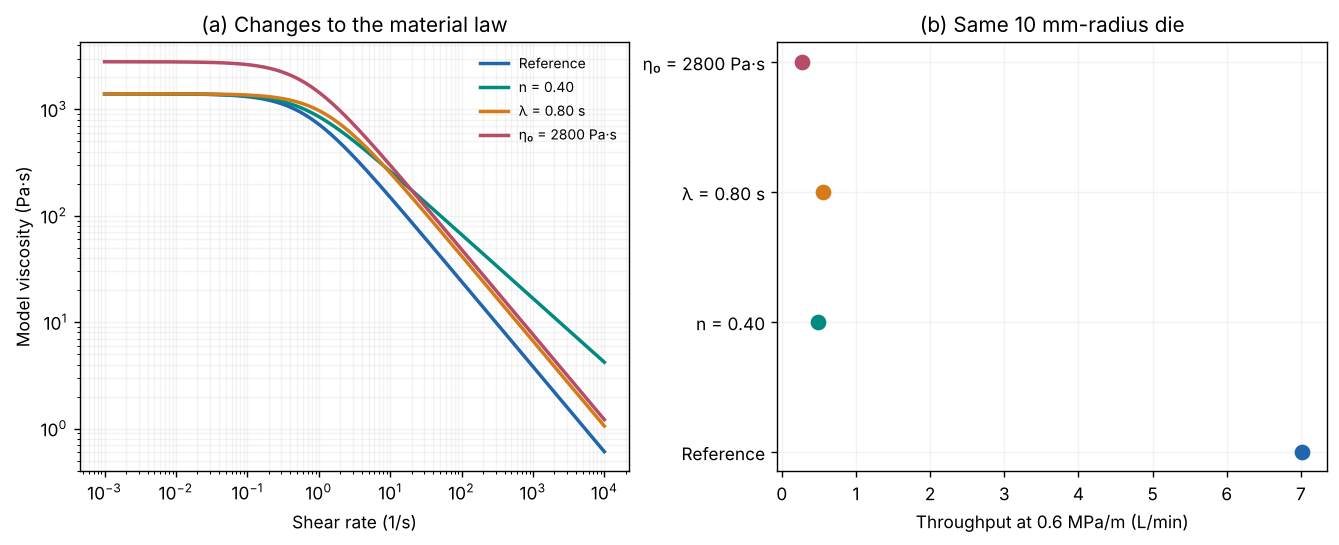

In [26]:
# Build two plots: one material property and one system-level output.
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.25), layout="constrained")
# Give each deliberate parameter change a consistent color across panels.
variant_colors = [colors["blue"], colors["teal"], colors["orange"], colors["rose"]]
# Iterate through names, materials, and corresponding colors together.
for (name, material), color in zip(material_variants.items(), variant_colors):
    # Calculate the changed fluid's viscosity at identical shear-rate inputs.
    axes[0].loglog(rate_grid_s_inv, viscosity_pa_s(rate_grid_s_inv, material), color=color, lw=2.0, label=name)
    # Read the independently computed throughput under fixed die conditions.
    throughput_l_min = variant_profiles[name]["Q_m3_s"] * 60000.0
    # Place a horizontal point to connect a parameter change to system flow.
    axes[1].scatter([throughput_l_min], [name], color=color, s=65, zorder=3)
# State the first plot's measured-style variable without treating it as data.
axes[0].set(xlabel="Shear rate (1/s)", ylabel="Model viscosity (Pa·s)", title="(a) Changes to the material law")
# State the fixed pressure and radius in the second plot title.
axes[1].set(xlabel="Throughput at 0.6 MPa/m (L/min)", title="(b) Same 10 mm-radius die")
# Separate line labels in a small readable legend.
axes[0].legend(frameon=False, fontsize=8)
# Use light grids only where they help compare values.
for ax in axes:
    # Keep each panel readable in a projected slide or printed page.
    ax.grid(alpha=0.14, which="both")
# Save an original two-level sensitivity illustration.
finish_figure(fig, "09_one_at_a_time_sensitivity")

**Figure 9.** A parameter can alter both the local rheological law and the useful die output. These examples compare one changed input at a time; simultaneous changes, fitted parameter uncertainty, wall slip, or heating could alter the conclusions.

## 9. Work backward from a production target

Processing often begins with a desired $Q$, not a chosen pressure. We can reuse bisection in a *second inverse problem*: find the pressure gradient $G$ for which the pipe solver returns $Q_{\rm target}$. A constant-$\eta_0$ material gives an upper pressure bracket here because the shear-thinning model has $\eta(\dot\gamma)\le\eta_0$. This bracket applies to the positive, monotone material parameters we chose. Let a hypothetical $0.30$ m straight die target **7.0 L/min**; its illustrative pressure loss is $\Delta p=GL$. Compare radii of 8, 10, and 12 mm. **Predict** whether a narrower passage requires more or less pressure for the same delivered volume.

In [27]:
# Define the pressure gradient needed for a specified positive volume rate.
def pressure_for_target_q_pa_m(target_q_m3_s, die_radius_m, material, points=801):
    '''Invert modeled Q(G) by bisection for a fixed die radius and material.'''
    # Require a physical positive flow and radius before searching.
    assert target_q_m3_s > 0.0 and die_radius_m > 0.0
    # Use zero pressure and zero throughput as the lower bracket.
    lower_pa_m = 0.0
    # Solve the constant-eta0 tube formula for pressure as an upper bracket.
    upper_pa_m = 8.0 * material["eta0_pa_s"] * target_q_m3_s / (np.pi * die_radius_m**4)
    # Ensure the chosen bracket reaches the target under the model.
    assert pipe_profile(upper_pa_m, die_radius_m, material, points=points)["Q_m3_s"] >= target_q_m3_s
    # Halve the pressure interval enough times for practical numerical precision.
    for _ in range(45):
        # Test the middle pressure in the original forward flow model.
        midpoint_pa_m = 0.5 * (lower_pa_m + upper_pa_m)
        # Compute a fresh flow rate, including its shear-dependent profile.
        midpoint_q_m3_s = pipe_profile(midpoint_pa_m, die_radius_m, material, points=points)["Q_m3_s"]
        # Raise the lower bound if the tested pressure underdelivers.
        if midpoint_q_m3_s < target_q_m3_s:
            # Keep only pressures above a point that produced too little flow.
            lower_pa_m = midpoint_pa_m
        # Otherwise the tested pressure is an admissible upper bound.
        else:
            # Keep only pressures below a point that met or exceeded the target.
            upper_pa_m = midpoint_pa_m
    # Report the center of the last small pressure interval in Pa/m.
    return 0.5 * (lower_pa_m + upper_pa_m)

In [28]:
# Convert a seven-litre-per-minute production target to cubic metres per second.
target_q_m3_s = 7.0 / 60000.0
# Treat the passage as a hypothetical 0.30 m long straight die.
die_length_m = 0.30
# Compare three inner radii while retaining the same material and volume rate.
candidate_radii_m = np.array([0.008, 0.010, 0.012])
# Solve the inverse problem for each candidate radius.
required_gradients_pa_m = np.array([pressure_for_target_q_pa_m(target_q_m3_s, r, fluid) for r in candidate_radii_m])
# Translate each solved gradient into a die-only pressure drop.
required_drops_pa = required_gradients_pa_m * die_length_m
# Print a small design comparison using millimetres and megapascals.
for r, gradient, pressure in zip(candidate_radii_m, required_gradients_pa_m, required_drops_pa):
    # Check the forward solver after solving this inverse problem.
    verified_q_m3_s = pipe_profile(gradient, r, fluid, points=1601)["Q_m3_s"]
    # Display radius, pressure loss per metre, finite-length loss, and throughput.
    print(f"R = {1000*r:4.0f} mm: G = {gradient/1e6:7.3f} MPa/m; Δp = {pressure/1e6:7.3f} MPa; Q = {60000*verified_q_m3_s:.4f} L/min")
    # Make an incorrect pressure or unit conversion fail visibly.
    assert np.isclose(verified_q_m3_s, target_q_m3_s, rtol=2e-5)
# Check the predicted direction when opening the passage at constant target Q.
assert np.all(np.diff(required_gradients_pa_m) < 0.0)

R =    8 mm: G =   0.858 MPa/m; Δp =   0.257 MPa; Q = 7.0000 L/min
R =   10 mm: G =   0.600 MPa/m; Δp =   0.180 MPa; Q = 7.0000 L/min
R =   12 mm: G =   0.448 MPa/m; Δp =   0.134 MPa; Q = 7.0000 L/min


In [29]:
# Apply the die-only pressure result to the 10 mm-radius design option.
pressure_drop_pa = required_drops_pa[1]
# Calculate the fluid pressure-work rate, pressure times volume per time.
ideal_die_power_w = pressure_drop_pa * target_q_m3_s
# Report the result in watts to illustrate energy dimensions.
print(f"10 mm option: die-only Δp = {pressure_drop_pa/1e6:.3f} MPa; pressure-work rate Δp Q = {ideal_die_power_w:.1f} W")
# Confirm the units algebra numerically with the selected target flow.
assert np.isclose(ideal_die_power_w / target_q_m3_s, pressure_drop_pa)

10 mm option: die-only Δp = 0.180 MPa; pressure-work rate Δp Q = 21.0 W


The $\Delta p Q$ figure describes **pressure work in this idealized straight segment**. It is not an extruder motor rating: entry and exit losses, heaters, screw motion, machine efficiency, changing temperature, and other equipment are absent. A larger radius may change shape or product requirements; the lowest pressure is not by itself a complete design.

## 10. What would a capillary-flow measurement suggest?

A short test tube can connect pressure and flow measurements to rheology. For a **Newtonian** pipe, the wall shear rate follows $\dot\gamma_{\rm app}=4Q/(\pi R^3)$, an estimate made from the observed $Q$ and geometry. It is often called the **apparent** wall rate when used with a non-Newtonian material. Our model also gives a **true model wall rate** by solving $\tau_w=\eta(\dot\gamma_w)\dot\gamma_w$. Compare the two without presenting their difference as measurement error; a nonparabolic flow profile is enough to separate them.

In [30]:
# Calculate the Newtonian-inferred apparent wall rate from the example flow.
apparent_wall_rate_s_inv = 4.0 * example["Q_m3_s"] / (np.pi * radius_m**3)
# Compare it with the actual rate selected by the model's wall stress.
rate_correction_factor = wall_rate_s_inv / apparent_wall_rate_s_inv
# State both rates and their unitless ratio with restrained precision.
print(f"Apparent wall rate = {apparent_wall_rate_s_inv:.2f} 1/s; model wall rate = {wall_rate_s_inv:.2f} 1/s")
# Describe the size of the correction in the present parameter example.
print(f"True-model/apparent rate = {rate_correction_factor:.3f}")
# The apparent and actual rates agree for a constant-viscosity reference.
newtonian_apparent_s_inv = 4.0 * newtonian_profile["Q_m3_s"] / (np.pi * radius_m**3)
# Calculate the independently predicted wall rate of that Newtonian case.
newtonian_wall_s_inv = gradient_pa_m * radius_m / (2.0 * fluid["eta0_pa_s"])
# Check that the Newtonian-based apparent expression is exact in its own limit.
assert np.isclose(newtonian_apparent_s_inv, newtonian_wall_s_inv, rtol=2e-6)

Apparent wall rate = 148.89 1/s; model wall rate = 296.53 1/s
True-model/apparent rate = 1.992


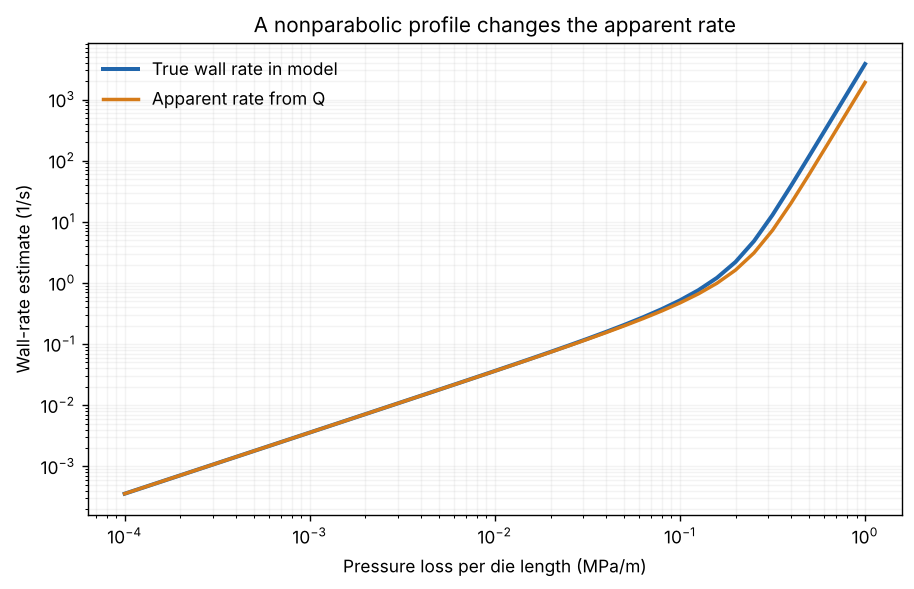

In [31]:
# Convert all pressure-sweep throughputs into Newtonian-inferred wall rates.
apparent_rates_s_inv = 4.0 * flow_q_m3_s / (np.pi * radius_m**3)
# Independently solve each pressure-sweep wall stress for its true model rate.
true_wall_rates_s_inv = shear_rate_from_stress_s_inv(gradient_values_pa_m * radius_m / 2.0, fluid)
# Plot both rates against the physical pressure gradient for direct comparison.
fig, ax = plt.subplots(figsize=(7.2, 4.6), layout="constrained")
# Draw the true rates found by inverting the model at the wall.
ax.loglog(gradient_values_pa_m / 1e6, true_wall_rates_s_inv, color=colors["blue"], lw=2.3, label="True wall rate in model")
# Draw the apparent rates inferred from the Newtonian pipe formula.
ax.loglog(gradient_values_pa_m / 1e6, apparent_rates_s_inv, color=colors["orange"], lw=2.0, label="Apparent rate from Q")
# Name the independently controlled horizontal variable and rate units.
ax.set(xlabel="Pressure loss per die length (MPa/m)", ylabel="Wall-rate estimate (1/s)", title="A nonparabolic profile changes the apparent rate")
# Keep both curves legible over many decades.
ax.grid(alpha=0.15, which="both")
# Place a line legend that separates the two definitions.
ax.legend(frameon=False, loc="upper left")
# Save and display the original capillary-rheometry illustration.
finish_figure(fig, "10_apparent_and_model_wall_rates")

**Figure 10.** The apparent rate is a useful first estimate, but a rheological interpretation needs the material response and the flow assumptions. In experimental capillary rheometry, entrance pressure loss, possible wall slip, temperature rise, and other corrections may also matter. We have no experimental measurements in this notebook.

## 11. Optional research connection: parameterize the whole profile by shear rate

The main notebook used bisection at every radius. The 2022 paper develops a complementary analytical route: use the shear rate $g$ itself as the parameter. Since the stress law is monotone, every $0\le g\le g_w$ maps to exactly one radius,

$$r(g)=R\frac{\tau(g)}{\tau_w}, \qquad
\frac{dr}{dg}=\frac{R}{\tau_w}\frac{d\tau}{dg}.$$

At $g=0$, $r=0$; at $g=g_w$, $r=R$. To recover the wall-zero speed while walking along the $g$ grid, we can add small changes $du=g\,dr$ in reverse. This connection is optional: its role is to show why a good choice of computational variable can simplify a nonlinear problem. **Predict:** should a plot of $r/R$ against $g/g_w$ be straight for our shear-thinning material?

In [32]:
# Sample shear rates continuously from the center value to the wall solution.
parameter_rates_s_inv = np.linspace(0.0, wall_rate_s_inv, 2401)
# Map each sampled shear rate to a radius using the known wall stress.
parameter_r_m = radius_m * flow_stress_pa(parameter_rates_s_inv, fluid) / wall_stress_pa
# Compute the derivative of radius with respect to rate from the model slope.
dr_drate_m_s = radius_m * flow_slope_pa_s(parameter_rates_s_inv, fluid) / wall_stress_pa
# Convert rate steps into corresponding positive speed increments.
parameter_du_m_s = 0.5 * (parameter_rates_s_inv[:-1] * dr_drate_m_s[:-1] + parameter_rates_s_inv[1:] * dr_drate_m_s[1:]) * np.diff(parameter_rates_s_inv)
# Add all increments from the center to each current rate, including zero.
forward_speed_changes_m_s = np.concatenate(([0.0], np.cumsum(parameter_du_m_s)))
# Subtract from the full integral to impose the wall's zero-speed boundary.
parameter_u_m_s = forward_speed_changes_m_s[-1] - forward_speed_changes_m_s
# Interpolate the earlier radial solver at these now nonuniform radii.
radial_solution_at_parameter_m_s = np.interp(parameter_r_m, example["r_m"], example["u_m_s"])
# Compare two distinct independent variables and integration grids.
parameter_speed_error = np.max(np.abs(parameter_u_m_s - radial_solution_at_parameter_m_s)) / example["u_max_m_s"]
# Print the dimensionless maximum disagreement so it has a clear scale.
print(f"Parametric versus radial profile: maximum speed discrepancy / center speed = {parameter_speed_error:.2e}")
# Verify the map includes both radius endpoints to numerical precision.
assert np.isclose(parameter_r_m[0], 0.0) and np.isclose(parameter_r_m[-1], radius_m)
# Catch a reversed map or missing derivative factor.
assert parameter_speed_error < 2e-5

Parametric versus radial profile: maximum speed discrepancy / center speed = 1.26e-05


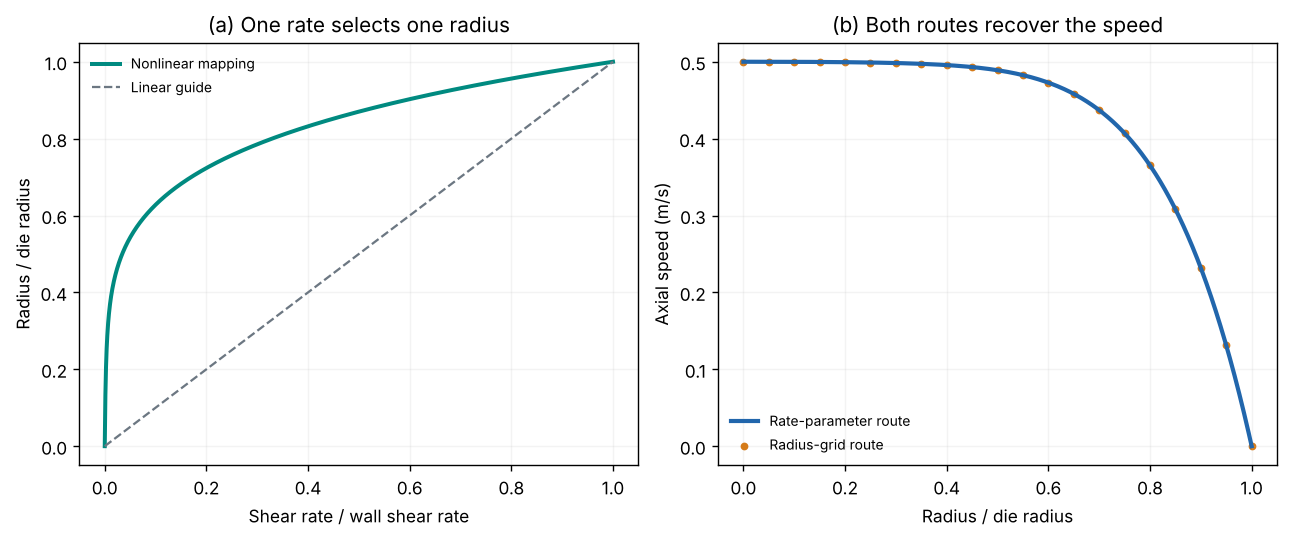

In [33]:
# Make the nonlinear mapping visible alongside its physical consequence.
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.2), layout="constrained")
# Draw normalized radius as a function of normalized shear-rate parameter.
axes[0].plot(parameter_rates_s_inv / wall_rate_s_inv, parameter_r_m / radius_m, color=colors["teal"], lw=2.3, label="Nonlinear mapping")
# Add the unit-slope line for comparison; it is not the material's answer.
axes[0].plot([0.0, 1.0], [0.0, 1.0], ls="--", color=colors["grey"], lw=1.3, label="Linear guide")
# Show the alternative speed integration as a continuous curve.
axes[1].plot(parameter_r_m / radius_m, parameter_u_m_s, color=colors["blue"], lw=2.4, label="Rate-parameter route")
# Add selected points from the earlier radius-grid calculation for validation.
axes[1].scatter(example["r_m"][::100] / radius_m, example["u_m_s"][::100], color=colors["orange"], s=12, label="Radius-grid route")
# Label the mapping axes with their dimensionless parameterization.
axes[0].set(xlabel="Shear rate / wall shear rate", ylabel="Radius / die radius", title="(a) One rate selects one radius")
# Label the recovered physical speed with its unit.
axes[1].set(xlabel="Radius / die radius", ylabel="Axial speed (m/s)", title="(b) Both routes recover the speed")
# Add compact legends and faint grids to each panel.
for ax in axes:
    # Describe which curves or points form the optional comparison.
    ax.legend(frameon=False, fontsize=8)
    # Give enough coordinate support without drawing attention from the data.
    ax.grid(alpha=0.14)
# Save the original picture of the research paper's change of variable.
finish_figure(fig, "11_rate_parameter_mapping")

The same mapping provides an independent flow integral by substituting $r=r(g)$ into $Q=\pi\int_0^R\dot\gamma(r)r^2dr$:

$$Q=\pi\int_0^{g_w}g\,[r(g)]^2\frac{dr}{dg}\,dg.$$

Here the circular cross-section contributes the $r^2$ weight. If the integral disagreed with the earlier two routes, we would revisit the stress derivative, radius mapping, or units.

In [34]:
# Form the rate-parameter integrand with the correct circular radius weight.
moment_integrand_m3_s = parameter_rates_s_inv * parameter_r_m**2 * dr_drate_m_s
# Integrate over rate and multiply by pi to recover the tube's volume rate.
parametric_q_m3_s = np.pi * np.trapezoid(moment_integrand_m3_s, parameter_rates_s_inv)
# Compare this parameter-based result against the earlier velocity-ring route.
parametric_q_relative_error = abs(parametric_q_m3_s / example["Q_m3_s"] - 1.0)
# State both values and the finite-grid disagreement in scientific notation.
print(f"Parametric Q = {parametric_q_m3_s:.9e} m³/s; radial Q = {example['Q_m3_s']:.9e} m³/s")
# Interpret the size of numerical rather than physical disagreement.
print(f"Relative disagreement = {parametric_q_relative_error:.2e}")
# Reject any missing radius weight or derivative in this third integration route.
assert parametric_q_relative_error < 2e-5

Parametric Q = 1.169352497e-04 m³/s; radial Q = 1.169352667e-04 m³/s
Relative disagreement = 1.45e-07


### An optional geometry thought experiment: tube or wide slit?

The 2026 **preprint**, which has not been peer reviewed, extends the analysis to a wide plane channel. Let $y$ run from its center to a wall a distance $R$ away. In a slit, $\tau(y)=G_{\rm slit}y$; in our tube, $\tau(r)=G_{\rm tube}r/2$. If $G_{\rm slit}=G_{\rm tube}/2$, the two have the **same wall stress and the same local speed curve** under the same material model and no-slip condition. Their *averages* still differ: a tube weighs outer rings by their circumference, whereas a wide slit gives equal area to equal-width strips across a half-gap:

$$\bar u_{\rm tube}=\frac{2}{R^2}\int_0^R u(r)r\,dr,
\qquad \bar u_{\rm slit}=\frac{1}{R}\int_0^R u(y)\,dy.$$

The slit result is an **average velocity**, not a volume flow until we specify a channel width and full gap. **Predict:** which geometry gives a larger average speed when both share the same center-to-wall speed curve?

In [35]:
# Match the slit wall stress to the original tube by halving its pressure gradient.
matching_slit_gradient_pa_m = gradient_pa_m / 2.0
# Average the already computed center-to-wall curve uniformly over a half-gap.
slit_mean_speed_m_s = np.trapezoid(example["u_m_s"], example["r_m"]) / radius_m
# Retain the original area-weighted circular-tube average for comparison.
tube_mean_speed_m_s = example["u_avg_m_s"]
# Print what was held equal and what differed between shapes.
print(f"Same wall stress = {matching_slit_gradient_pa_m * radius_m:.0f} Pa")
# Show both physical mean speeds at their matching wall conditions.
print(f"Tube mean = {tube_mean_speed_m_s:.4f} m/s; wide-slit mean = {slit_mean_speed_m_s:.4f} m/s")
# Check the expected area-weight effect for this monotone speed profile.
assert slit_mean_speed_m_s > tube_mean_speed_m_s
# Compute the independent exact Newtonian slit mean at the matched stress.
newtonian_slit_mean_m_s = matching_slit_gradient_pa_m * radius_m**2 / (3.0 * fluid["eta0_pa_s"])
# Verify the Newtonian tube mean on the same wall-stress basis.
assert np.isclose(newtonian_profile["u_avg_m_s"], matching_slit_gradient_pa_m * radius_m**2 / (4.0 * fluid["eta0_pa_s"]), rtol=2e-6)
# Show the expected 4/3 relation between the slit and tube Newtonian means.
assert np.isclose(newtonian_slit_mean_m_s / newtonian_profile["u_avg_m_s"], 4.0 / 3.0, rtol=2e-6)

Same wall stress = 3000 Pa
Tube mean = 0.3722 m/s; wide-slit mean = 0.4264 m/s


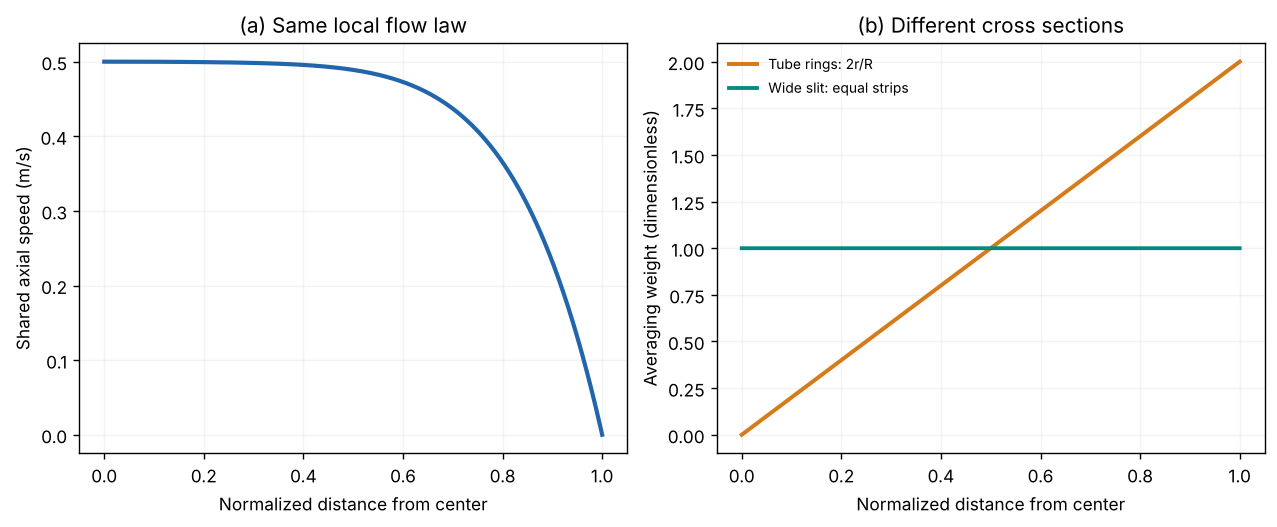

In [36]:
# Compare the same local speed curve under the two cross-sectional weights.
fig, axes = plt.subplots(1, 2, figsize=(10.1, 4.1), layout="constrained")
# Show the common profile whose shape is held equal in this thought experiment.
axes[0].plot(example["r_m"] / radius_m, example["u_m_s"], color=colors["blue"], lw=2.4)
# Plot the tube's normalized area weight for a ring at r/R.
axes[1].plot(example["r_m"] / radius_m, 2.0 * example["r_m"] / radius_m, color=colors["orange"], lw=2.3, label="Tube rings: 2r/R")
# Plot the wide slit's normalized equal-strip weight.
axes[1].plot(example["r_m"] / radius_m, np.ones_like(example["r_m"]), color=colors["teal"], lw=2.2, label="Wide slit: equal strips")
# Label the shared physical speed panel in metres per second.
axes[0].set(xlabel="Normalized distance from center", ylabel="Shared axial speed (m/s)", title="(a) Same local flow law")
# Label geometry weights as dimensionless so they are not mistaken for speeds.
axes[1].set(xlabel="Normalized distance from center", ylabel="Averaging weight (dimensionless)", title="(b) Different cross sections")
# Explain which weight belongs to each geometry in a compact legend.
axes[1].legend(frameon=False, fontsize=8)
# Provide restrained grids to assist area-weight reasoning.
for ax in axes:
    # Improve read-off without visually overpowering the curves.
    ax.grid(alpha=0.14)
# Save the original plot of geometry-controlled averaging.
finish_figure(fig, "12_same_profile_different_geometry")

**Figure 12.** This is a controlled comparison at the same wall stress, not a claim that a real plane slit and circular die can be swapped while holding all other machine details fixed. The outer part of a tube occupies more cross-sectional area, and its lower local speed pulls the mean down.

### A compact formula from the later preprint (optional)

The later preprint gives a special-function expression for the *mean* tube speed when $\eta_\infty=0$. Let $d=\eta_0/\eta(g_w)$ and $z=-(\lambda g_w)^a$. Its Eq. (31), expressed with our dimensional variables, is

$$\frac{\bar u}{Rg_w}=\frac{1}{3}\left[1-\frac{d^3}{4}\,{}_2F_1\!\left(\frac4a,\frac{3(1-n)}a;1+\frac4a;z\right)\right].$$

The function ${}_2F_1$ is a **hypergeometric function**, supplied by SciPy; no derivation is expected here. The code below compares an independent published expression with our numerical integration for this *particular* zero-$\eta_\infty$ example. It does not make the 2026 preprint peer reviewed, nor does it validate the physical assumptions against experiments.

In [37]:
# Load SciPy's documented Gaussian hypergeometric evaluator for this optional check.
from scipy.special import hyp2f1
# Confirm the preprint formula's stated zero high-rate-viscosity condition.
assert fluid["eta_inf_pa_s"] == 0.0
# Form the ratio of low-rate to wall viscosity in the paper's expression.
wall_viscosity_ratio = fluid["eta0_pa_s"] / wall_viscosity_pa_s
# Evaluate the unitless negative argument at the solved wall rate.
hypergeometric_argument = -(fluid["lambda_s"] * wall_rate_s_inv) ** fluid["a"]
# Evaluate the preprint's dimensionless mean-speed expression.
mean_over_wall_scale = (1.0 - wall_viscosity_ratio**3 * hyp2f1(4.0 / fluid["a"], 3.0 * (1.0 - fluid["n"]) / fluid["a"], 1.0 + 4.0 / fluid["a"], hypergeometric_argument) / 4.0) / 3.0
# Restore metres per second using radius times wall rate as the speed scale.
hypergeometric_mean_m_s = radius_m * wall_rate_s_inv * mean_over_wall_scale
# Compare the independent special-function evaluation to radial quadrature.
print(f"Preprint Eq. (31) mean speed = {hypergeometric_mean_m_s:.8f} m/s")
# Print the main numerical result on the same dimensional basis.
print(f"Numerical ring-integral mean = {example['u_avg_m_s']:.8f} m/s")
# Detect a coefficient, exponent, or unit mistake in transcription.
assert np.isclose(hypergeometric_mean_m_s, example["u_avg_m_s"], rtol=2e-5)

Preprint Eq. (31) mean speed = 0.37221645 m/s
Numerical ring-integral mean = 0.37221651 m/s


## 12. Try it yourself: prediction, computation, explanation

1. **A different radius.** Before changing code, predict whether reducing $R$ from 10 to 9 mm at the same $G$ raises or lowers $Q$. Compute the change and explain why the result is more informative than comparing radii alone. Report $R$, $G$, and $Q$ with units.
2. **The low-shear limit.** Reduce $G$ until the model $Q$ nearly matches constant-$\eta_0$ Poiseuille flow. State a numerical agreement criterion you chose. Why does the original $0.6$ MPa/m example differ?
3. **A bounded plateau.** Set $\eta_\infty$ to 50 Pa·s, leave every other parameter unchanged, and compare $u_{\max}/\bar u$ as $G$ grows. Describe why the zero-$\eta_\infty$ high-rate limit is no longer the right ultimate shape.
4. **A careful claim.** Imagine a real polymer melt shows 8 L/min in a test die. Identify two experimental measurements and two model assumptions you would need before using this notebook to predict another die. Which conclusions follow only from mathematics, and which need validation against data?

The next executable cell is a worked starting point for Activity 1. Modify a **copy** of it for other radii. When a result surprises you, check the SI units, constant inputs, and the `assert` statements before drawing a physical conclusion.

In [38]:
# Select a 9 mm-radius follow-up while holding gradient and material fixed.
exercise_radius_m = 0.009
# Reuse the same verified solver to get the revised throughput.
exercise_profile = pipe_profile(gradient_pa_m, exercise_radius_m, fluid)
# Compute the ratio so students can explain the size of the response.
exercise_q_ratio = exercise_profile["Q_m3_s"] / example["Q_m3_s"]
# Print all controlled and measured variables with their dimensions.
print(f"G = {gradient_pa_m / 1e6:.2f} MPa/m; R = {1000 * exercise_radius_m:.1f} mm; Q = {60000 * exercise_profile['Q_m3_s']:.3f} L/min")
# Compare to the baseline's reported volume per minute.
print(f"Q(9 mm) / Q(10 mm) = {exercise_q_ratio:.3f}")
# Catch the physical direction for a smaller opening under fixed pressure.
assert 0.0 < exercise_q_ratio < 1.0

G = 0.60 MPa/m; R = 9.0 mm; Q = 3.035 L/min
Q(9 mm) / Q(10 mm) = 0.433


## What we learned, and where the model ends

| Connection | Code or equation | Engineering interpretation |
| --- | --- | --- |
| Geometry and units | $Q=\pi R^2\bar u$ | Throughput is a volume rate, not a local speed. |
| Force balance | $\tau(r)=Gr/2$ | Pressure and radius set the stress within this ideal tube. |
| Rheology | $\tau=\eta(\dot\gamma)\dot\gamma$ | The material response turns stress into local deformation. |
| Speed and flow | $u(r)=\int_r^R\dot\gamma(s)ds$; ring integration | Boundary conditions and geometry turn local behavior into system output. |
| Scientific computing | Brackets, two flow integrals, Newtonian limit, grid refinement | Numerical results become more trustworthy through independent checks. |
| Processing decision | Solve $Q(G,R)=Q_{\rm target}$ | A target delivery rate suggests a die-only pressure estimate under stated assumptions. |

**Scope.** This is a steady, isothermal, fully developed, laminar, incompressible, generalized-Newtonian flow with a fixed circular die, no slip, and a single fluid whose material parameters are constant. It ignores elastic memory, normal stresses, entry and exit effects, heating and cooling, crystallization, melting, thermal degradation, pressure dependence of viscosity, wall slip, gravity, changing geometry, and machine performance. Polymer melts can display several of these effects. The notebook teaches a tractable *slice* of rheology and processing, not a complete extruder simulation or an experimentally validated design. For measured melts, fit and validate parameters against data in the relevant temperature and rate range.

**Sources and attribution.** Primary research: Y. Wang, “Steady isothermal flow of a Carreau–Yasuda model fluid in a straight circular tube,” *J. Non-Newtonian Fluid Mech.* 310 (2022), 104937, [doi:10.1016/j.jnnfm.2022.104937](https://doi.org/10.1016/j.jnnfm.2022.104937). Implementation reference: [ktwyw/carreau-yasuda-pipe-flow](https://github.com/ktwyw/carreau-yasuda-pipe-flow), especially its model, numerical solver, and worked example. Optional mathematical extension: Y. Wang, “A Hypergeometric Integral Framework for Pressure-Driven Carreau–Yasuda Flow in Circular Tubes and Plane Channels,” [2026 preprint, doi:10.20944/preprints202608.2093.v1](https://doi.org/10.20944/preprints202608.2093.v1), *not peer reviewed*. The comparisons and plots in this notebook are instructional reproductions using newly written code and illustrative parameters; no experimental data are claimed.